# DE et PSO sur CPU et GPU — protocole commun

Notebook autonome : sources embarquées, compilation, tests algorithmiques, mesures,
analyse et archive. Aucune campagne historique n'est importée ; les quatre implémentations
sont remesurées dans la même session et sur la même machine.

- DE/rand/1/bin générationnel : F=0,5, CR=0,3, trois donneurs distincts excluant la cible.
- PSO synchrone : ω de 0,9 à 0,4, c1=c2=2, vmax=0,2×(hi−lo).
- Double précision ; fonctions décalées communes ; RNG CPU mt19937_64, GPU Philox.
- Grille : 4 fonctions × dimensions 10/50/100 × populations 50/100/500 × 10 runs.
- Budget : P×(1+nGen) ≤ 10⁴×D ; identifiants de runs 1234..1243.
- Graines moteur dérivées par SplitMix64 avec un identifiant de flux par implémentation ;
  `seed` et `engine_seed` sont tous deux exportés. Cela évite de partager une population
  initiale entre DE CPU et PSO CPU lors des tests pour échantillons indépendants.

Par défaut, seuls les builds et tests sont exécutés. Activer `RUN_FULL_SWEEPS=True`
pour les campagnes. `RUN_DE_GPU=True` active **DE GPU et PSO GPU** ; choisir False
sur une machine sans CUDA. Chaque configuration GPU chauffe et mesure dans le même processus.
Les temps mesurent le calcul, avec allocations et transferts exclus ; ils ne sont pas des temps
applicatifs de bout en bout. Les flux aléatoires CPU/GPU diffèrent : aucune égalité des trajectoires
n'est attendue. La reproductibilité exacte nécessite le même environnement logiciel et matériel ;
les distributions de la bibliothèque C++ ne sont pas garanties identiques entre plateformes.

Chaque exécution de la configuration crée un dossier `de_pso_work/<session>/` isolé.
Exécuter les cellules dans l'ordre. Prérequis : Python, numpy, pandas, matplotlib,
SciPy ≥ 1.13 (Mann–Whitney avec permutations), g++ ; nvcc et GPU NVIDIA si activés.
Le DE CUDA reste une référence ; les optimisations cudaDEi de l'article sont hors périmètre.


## 1. Configuration, prérequis et outils d’exécution


In [28]:
from pathlib import Path
import csv
import hashlib
import importlib
import itertools
import json
import math
import platform
import re
import shutil
import subprocess
import sys
import time
import uuid

SESSION_ID = time.strftime("%Y%m%dT%H%M%SZ", time.gmtime()) + "_" + uuid.uuid4().hex[:8]
WORK_DIR = Path.cwd() / "de_pso_work" / SESSION_ID
ON_KAGGLE = Path("/kaggle").exists()
RUN_DE_GPU = True
RUN_FULL_SWEEPS = True        # False : compilations et tests uniquement
CUDA_ARCH = None               # détection automatique ; exemple de valeur explicite : "sm_75"
RUN_TIMEOUT_SECONDS = 600
RUNS = 10
DIMS, POPS = [10, 50, 100], [50, 100, 500]
# Échauffement dans le même processus CUDA, immédiatement avant les mesures :
# au moins WARMUP_MIN_RUNS exécutions et WARMUP_SECONDS cumulés par configuration,
# plafonnées à WARMUP_MAX_RUNS ; graines de warm-up jamais utilisées en mesure.
WARMUP_MIN_RUNS, WARMUP_SECONDS, WARMUP_MAX_RUNS = 3, 2.0, 10000
WARMUP_SEED0 = 910000
FUNCS = {4: "Sphere", 1: "Rastrigin", 2: "Rosenbrock", 3: "Griewank"}
BIAS = {4: -450.0, 1: -330.0, 2: 390.0, 3: -180.0}
COLS = ["algo", "func", "dim", "pop", "run", "seed", "engine_seed", "fe", "best", "error", "time_ms"]

for package in ("numpy", "pandas", "matplotlib", "scipy"):
    try:
        importlib.import_module(package)
    except ImportError as exc:
        raise RuntimeError(f"Installer les dépendances : pip install numpy pandas matplotlib scipy ({package} absent)") from exc
import numpy as np
import pandas as pd
from scipy import stats as spstats
try:
    spstats.mannwhitneyu([0.0, 1.0], [1.0, 2.0],
                        method=spstats.PermutationMethod(n_resamples=9,random_state=0))
except (AttributeError, TypeError, ValueError) as exc:
    raise RuntimeError("SciPy >= 1.13 requis pour Mann–Whitney avec permutations") from exc
if shutil.which("g++") is None:
    raise RuntimeError("g++ introuvable : installer un compilateur C++")
if not math.isfinite(RUN_TIMEOUT_SECONDS) or RUN_TIMEOUT_SECONDS <= 0:
    raise ValueError("RUN_TIMEOUT_SECONDS doit être positif")
if not isinstance(RUNS, int) or RUNS < 1 or not DIMS or not POPS or not FUNCS:
    raise ValueError("Configuration vide ou RUNS invalide")
if any(not isinstance(d, int) or d < 1 for d in DIMS):
    raise ValueError("Les dimensions doivent être des entiers positifs")
if any(not isinstance(p, int) or p < 4 or p > 10000 * min(DIMS) for p in POPS):
    raise ValueError("DE nécessite une population >= 4, inférieure au budget")
if RUN_DE_GPU and max(POPS) > 1024:
    raise ValueError("Le PSO GPU de référence exige une population <= 1024")
if any(f not in BIAS for f in FUNCS):
    raise ValueError("Fonction non prise en charge dans le sweep")
if any(len(values) != len(set(values)) for values in (DIMS, POPS)):
    raise ValueError("Dimensions et populations ne doivent pas contenir de doublons")
if WARMUP_MIN_RUNS < 1 or WARMUP_MAX_RUNS < WARMUP_MIN_RUNS or not (WARMUP_SECONDS >= 0):
    raise ValueError("Warm-up invalide : min >= 1, plafond >= min, secondes >= 0")
if not WARMUP_SEED0 >= 1234 + RUNS:
    raise ValueError("Graines de warm-up hors des graines mesurées 1234..1234+RUNS-1")

def checked(command, cwd=None):
    command = [str(x) for x in command]
    try:
        result = subprocess.run(command, cwd=cwd, text=True, stdout=subprocess.PIPE,
                                stderr=subprocess.STDOUT, timeout=RUN_TIMEOUT_SECONDS)
    except subprocess.TimeoutExpired as exc:
        raise RuntimeError(f"Délai dépassé ({RUN_TIMEOUT_SECONDS}s) : {command}") from exc
    if result.returncode:
        raise RuntimeError(f"Commande échouée ({result.returncode}) : {command}\n{result.stdout}")
    return result.stdout

print(checked(["g++", "--version"]))
if RUN_DE_GPU:
    for tool in ("nvcc", "nvidia-smi"):
        if shutil.which(tool) is None:
            raise RuntimeError(f"{tool} introuvable : activer le GPU Kaggle, ou RUN_DE_GPU=False")
    print(checked(["nvidia-smi"]))
    print(checked(["nvcc", "--version"]))
    if CUDA_ARCH is None:
        caps = checked(["nvidia-smi", "--query-gpu=compute_cap", "--format=csv,noheader"])
        caps = {line.strip() for line in caps.splitlines() if line.strip()}
        if len(caps) != 1 or not re.fullmatch(r"[0-9]+\.[0-9]+", next(iter(caps))):
            raise RuntimeError("Architecture non détectée ou GPU hétérogènes : préciser CUDA_ARCH")
        CUDA_ARCH = "sm_" + caps.pop().replace(".", "")
    if not re.fullmatch(r"sm_[0-9]+", CUDA_ARCH):
        raise ValueError("CUDA_ARCH doit avoir la forme sm_75")

DE_SRC = WORK_DIR / "de" / "src"
DE_BUILD = WORK_DIR / "de" / "build"
PSO_SRC = WORK_DIR / "pso_cpu" / "src"
PSO_BUILD = WORK_DIR / "pso_cpu" / "build"
RESULTS_DIR = WORK_DIR / "results"
for directory in (DE_SRC, DE_BUILD, PSO_SRC, PSO_BUILD, RESULTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

def write_sources(directory, sources):
    for name, content in sources.items():
        if Path(name).name != name or "TODO: Collez" in content:
            raise ValueError(f"Source invalide ou incomplète : {name}")
        for include in re.findall(r'^\s*#include\s+"([^"]+)"', content, re.MULTILINE):
            if include not in sources:
                raise ValueError(f"Include local absent : {include} dans {name}")
    expected = set(sources) | {"sources.sha256.json"}
    for stale in directory.iterdir():
        if stale.is_file() and stale.name not in expected:
            stale.unlink()
    hashes = {}
    for name, content in sources.items():
        data = content.encode("utf-8")
        (directory / name).write_bytes(data)
        hashes[name] = hashlib.sha256(data).hexdigest()
        print(f"{directory / name} — SHA-256 {hashes[name][:12]}")
    (directory / "sources.sha256.json").write_text(json.dumps(hashes, indent=2))
    return hashes

def verify_sources(directory, hashes):
    for name, digest in hashes.items():
        if hashlib.sha256((directory / name).read_bytes()).hexdigest() != digest:
            raise RuntimeError(f"Source modifiée : {directory / name}. Régénérer et recompiler.")

COMPLETED_RESULTS = {}  # ne pas analyser silencieusement les résultats d'une ancienne session
print("Fichiers générés :", WORK_DIR)
print("Mode :", "CPU + DE GPU + PSO GPU" if RUN_DE_GPU else "CPU uniquement")


g++ (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0
Copyright (C) 2023 Free Software Foundation, Inc.
This is free software; see the source for copying conditions.  There is NO
warranty; not even for MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.


Mon Oct 26 08:49:08 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |         

## 2. Sources DE embarquées

Fonctions communes au PSO, DE/rand/1/bin générationnel sur CPU et GPU, donneurs distincts
excluant la cible, mutation avec clamping et croisement binomial avec une coordonnée forcée.
Le CPU construit un tampon P×D complet avant sélection ; les kernels GPU séparent construction
et sélection. Philox conserve son état après initialisation et entre générations.
`de_ops.h` partage les règles de donneurs et de mutation entre CPU et GPU.
Les sources incluent les exécutables de tests et le pilote de campagne.


In [29]:
DE_REFERENCE_SHA256 = {'kernel.h': '054480ad337076db26871f00fd881a6e46aaa10adaf7d60f694f26a1560ca6ef', 'kernel.cpp': '1b3c6b82318e948bda3319e5d1622728a04342a141820f16f2743331b4e811cc'}
DE_SOURCES = {
    'kernel.h': r'''#pragma once
// ============================================================================
//  Massively parallel PSO (CUDA) - benchmark protocol of the M2 project
//  Objective functions : see bench_info() / fitness() below
// ============================================================================
#include <cmath>
#include <cstdio>
#include <cstdlib>
#include <string>
#include <vector>

#ifdef __CUDACC__
  #define HD __host__ __device__
#else
  #define HD
#endif

// Precision of the swarm state. The fitness is ALWAYS accumulated in double
// (needed to reach errors ~1e-8 around biases such as -450).
// Compile with -DUSE_FLOAT for a pure single-precision swarm.
#ifdef USE_FLOAT
typedef float  real;
#else
typedef double real;
#endif

// ---------------------------------------------------------------------------
// Objective functions (same numbering as the original code)
//   0 : Levy                  (extra, not in the official protocol)
//   1 : Shifted Rastrigin     [-5, 5]^D        f* = -330
//   2 : Shifted Rosenbrock    [-100, 100]^D    f* =  390
//   3 : Shifted Griewank      [-600, 600]^D    f* = -180
//   4 : Shifted Sphere        [-100, 100]^D    f* = -450
// ---------------------------------------------------------------------------
enum ObjFunc { F_LEVY = 0, F_RASTRIGIN = 1, F_ROSENBROCK = 2, F_GRIEWANK = 3, F_SPHERE = 4 };

HD inline double f_bias(int func)
{
    switch (func) {
        case F_RASTRIGIN:  return -330.0;
        case F_ROSENBROCK: return  390.0;
        case F_GRIEWANK:   return -180.0;
        case F_SPHERE:     return -450.0;
        default:           return 0.0;
    }
}

// x[k * stride] is the k-th coordinate (stride = 1 on the host, stride = P on
// the GPU because the swarm is stored coordinate-major for coalesced access).
// o = shift vector (ignored by Levy).  One single implementation for CPU+GPU.
HD inline double fitness(const real* x, int stride, int D, int func, const real* o)
{
    const double PI = 3.14159265358979323846;
    double res = 0.0;

    switch (func) {
    case F_LEVY: {
        double w1 = 1.0 + ((double)x[0] - 1.0) / 4.0;
        double s  = sin(PI * w1);
        res = s * s;
        for (int i = 0; i < D - 1; i++) {
            double wi = 1.0 + ((double)x[i * stride] - 1.0) / 4.0;
            double t  = sin(PI * wi + 1.0);
            res += (wi - 1.0) * (wi - 1.0) * (1.0 + 10.0 * t * t);
        }
        double wd = 1.0 + ((double)x[(D - 1) * stride] - 1.0) / 4.0;
        double sd = sin(2.0 * PI * wd);
        res += (wd - 1.0) * (wd - 1.0) * (1.0 + sd * sd);
        break;
    }
    case F_RASTRIGIN: {
        for (int i = 0; i < D; i++) {
            double z = (double)x[i * stride] - (double)o[i];
            res += z * z - 10.0 * cos(2.0 * PI * z) + 10.0;
        }
        break;
    }
    case F_ROSENBROCK: {
        for (int i = 0; i < D - 1; i++) {
            double zi  = (double)x[i * stride]       - (double)o[i]     + 1.0;
            double zi1 = (double)x[(i + 1) * stride] - (double)o[i + 1] + 1.0;
            double a = zi * zi - zi1;
            double b = zi - 1.0;
            res += 100.0 * a * a + b * b;
        }
        break;
    }
    case F_GRIEWANK: {
        double sum = 0.0, prod = 1.0;          // prod MUST start at 1 (was 0 in v1)
        for (int i = 0; i < D; i++) {
            double z = (double)x[i * stride] - (double)o[i];
            sum  += z * z / 4000.0;
            prod *= cos(z / sqrt((double)(i + 1)));
        }
        res = sum - prod + 1.0;
        break;
    }
    case F_SPHERE: {
        for (int i = 0; i < D; i++) {
            double z = (double)x[i * stride] - (double)o[i];
            res += z * z;
        }
        break;
    }
    }
    return res + f_bias(func);
}

// ---------------------------------------------------------------------------
// Host-side helpers (kernel.cpp)
// ---------------------------------------------------------------------------
struct BenchInfo { const char* name; double lo, hi, bias; };
BenchInfo bench_info(int func);

// mode : "zero" | "rand" | "file:<path>"   (file = CEC2005 shift vector, first D values)
bool   make_shift(int func, int dim, const std::string& mode, std::vector<real>& o);
double host_fitness(const std::vector<real>& x, int func, const std::vector<real>& o);

// ---------------------------------------------------------------------------
// PSO (kernel.cu)
// ---------------------------------------------------------------------------
struct PSOParams {
    int       func   = F_SPHERE;
    int       dim    = 10;
    int       pop    = 50;                 // 2 .. 1024
    long long maxFE  = 100000;             // protocol : 10^4 * dim
    double    wMax   = 0.9, wMin = 0.4;    // inertia, linearly decreasing
    double    c1     = 2.0,  c2   = 2.0;
    double    vmaxFrac = 0.2;              // |v| <= vmaxFrac * (hi - lo)
    unsigned long long seed = 1234ULL;
};

struct PSOResult {
    double            bestFit = 0.0;
    double            timeMs  = 0.0;       // GPU time measured with cudaEvent
    long long         fe      = 0;         // function evaluations really used
    int               iters   = 0;
    std::vector<real> gBest;
};

PSOResult cuda_pso(const PSOParams& prm, const std::vector<real>& shift);   // kernel.cu (GPU)
PSOResult seq_pso (const PSOParams& prm, const std::vector<real>& shift);   // pso_seq.cpp (CPU, 1 thread)
''',
    'kernel.cpp': r'''#include "kernel.h"
#include <chrono>
#include <fstream>
#include <random>

BenchInfo bench_info(int func)
{
    switch (func) {
        case F_LEVY:       return { "Levy",       -10.0,   10.0,    0.0 };
        case F_RASTRIGIN:  return { "Rastrigin",   -5.0,    5.0, -330.0 };
        case F_ROSENBROCK: return { "Rosenbrock", -100.0,  100.0,  390.0 };
        case F_GRIEWANK:   return { "Griewank",   -600.0,  600.0, -180.0 };
        case F_SPHERE:     return { "Sphere",     -100.0,  100.0, -450.0 };
        default:           return { "?", 0, 0, 0 };
    }
}

// Shift vector o :  z = x - o, optimum at x* = o, f(x*) = bias.
//  "zero"       : o = 0 (behaviour of the original code)
//  "rand"       : reproducible o_i in [0.8*lo, 0.8*hi] (fixed seed, prefix-stable in dim)
//  "file:<path>": first `dim` numbers of a CEC2005 data file (e.g. sphere_func_data.txt)
bool make_shift(int func, int dim, const std::string& mode, std::vector<real>& o)
{
    o.assign(dim, (real)0);
    if (func == F_LEVY || mode == "zero") return true;

    BenchInfo b = bench_info(func);
    if (mode == "rand") {
        std::mt19937_64 gen(20261027ULL + (unsigned)func);
        std::uniform_real_distribution<double> U(0.8 * b.lo, 0.8 * b.hi);
        for (int i = 0; i < dim; i++) o[i] = (real)U(gen);
        return true;
    }
    if (mode.rfind("file:", 0) == 0) {
        std::ifstream f(mode.substr(5));
        if (!f) { fprintf(stderr, "cannot open shift file %s\n", mode.c_str() + 5); return false; }
        double v;
        for (int i = 0; i < dim; i++) {
            if (!(f >> v)) { fprintf(stderr, "shift file has fewer than %d values\n", dim); return false; }
            o[i] = (real)v;
        }
        return true;
    }
    fprintf(stderr, "unknown shift mode '%s'\n", mode.c_str());
    return false;
}

// Same code as the GPU one (kernel.h) -> used to double-check the GPU result.
double host_fitness(const std::vector<real>& x, int func, const std::vector<real>& o)
{
    return fitness(x.data(), 1, (int)x.size(), func, o.data());
}


// ============================================================================
//  Sequential PSO (CPU, 1 thread) - reference implementation, compiled with the
//  rest of kernel.cpp (build with -DSEQUENTIAL to use it from main.cpp).
//  Same algorithm, parameters, budget and output as the CUDA version (kernel.cu):
//    - synchronous PSO : gBest is updated once per generation, after all pBest
//    - independent r1, r2 per particle AND per dimension
//    - inertia decreasing linearly wMax -> wMin, velocity and position clamping
//    - FEs = P * (1 + nIter) <= MaxFEs
//  Only the RNG differs (mt19937_64 here, cuRAND Philox on the GPU): results are
//  not bit-identical; statistical agreement must be assessed experimentally.
//  Memory layout is particle-major (p*D + d), the cache-friendly one on a CPU.
// ============================================================================
PSOResult seq_pso(const PSOParams& prm, const std::vector<real>& shift)
{
    const int P = prm.pop, D = prm.dim;
    if (P < 2 || D < 1 || (int)shift.size() < D) {
        fprintf(stderr, "seq_pso: invalid parameters (pop >= 2, dim >= 1)\n");
        exit(1);
    }
    const BenchInfo bi = bench_info(prm.func);
    const size_t n = (size_t)P * D;
    const real lo   = (real)bi.lo, hi = (real)bi.hi;
    const real vmax = (real)(prm.vmaxFrac * (bi.hi - bi.lo));
    const real c1 = (real)prm.c1, c2 = (real)prm.c2;

    long long nIter = prm.maxFE / P - 1;           // initial evaluation costs P FEs
    if (nIter < 0) nIter = 0;

    std::mt19937_64 gen(prm.seed);
    std::uniform_real_distribution<real> U01((real)0, (real)1);

    std::vector<real>   pos(n), vel(n, (real)0), pbest(n), gbest(D, (real)0);
    std::vector<double> pfit(P, 1.0e300);
    double gfit = 1.0e300;

    // evaluation + pBest update (kernel E on the GPU)
    auto evaluate = [&]() {
        for (int p = 0; p < P; p++) {
            double f = fitness(&pos[(size_t)p * D], 1, D, prm.func, shift.data());
            if (f < pfit[p]) {
                pfit[p] = f;
                for (int d = 0; d < D; d++) pbest[(size_t)p * D + d] = pos[(size_t)p * D + d];
            }
        }
    };
    // gBest = argmin of pBest fitness (kernel G on the GPU)
    auto reduce_gbest = [&]() {
        int b = 0;
        for (int p = 1; p < P; p++) if (pfit[p] < pfit[b]) b = p;
        if (pfit[b] < gfit) {
            gfit = pfit[b];
            for (int d = 0; d < D; d++) gbest[d] = pbest[(size_t)b * D + d];
        }
    };

    auto t0 = std::chrono::steady_clock::now();

    // initialisation (kernel I)
    for (size_t e = 0; e < n; e++) {
        pos[e]   = lo + (hi - lo) * U01(gen);
        pbest[e] = pos[e];
    }
    evaluate();
    reduce_gbest();

    // main loop
    for (long long it = 0; it < nIter; it++) {
        const real w = (real)((nIter > 1)
            ? prm.wMax - (prm.wMax - prm.wMin) * (double)it / (double)(nIter - 1)
            : prm.wMax);

        // velocity & position update (kernel U)
        for (int p = 0; p < P; p++) {
            for (int d = 0; d < D; d++) {
                const size_t e = (size_t)p * D + d;
                const real r1 = U01(gen), r2 = U01(gen);
                real x = pos[e];
                real v = w * vel[e] + c1 * r1 * (pbest[e] - x) + c2 * r2 * (gbest[d] - x);
                if (v >  vmax) v =  vmax;
                if (v < -vmax) v = -vmax;
                x += v;
                if (x < lo)      { x = lo; v = (real)0; }
                else if (x > hi) { x = hi; v = (real)0; }
                vel[e] = v;
                pos[e] = x;
            }
        }
        evaluate();
        reduce_gbest();
    }

    auto t1 = std::chrono::steady_clock::now();

    PSOResult r;
    r.bestFit = gfit;
    r.gBest   = gbest;
    r.timeMs  = std::chrono::duration<double, std::milli>(t1 - t0).count();
    r.iters   = (int)nIter;
    r.fe      = (long long)P * (1 + nIter);
    return r;
}
''',
    'de.h': r'''#ifndef DE_H
#define DE_H

// Reference DE of the M2 protocol, sharing kernel.h with the PSO: same shifted
// functions, same bounds, same shift mode, same double precision, same budget.
//   - DE/rand/1/bin, F = 0.5, CR = 0.3 (values of the reference article)
//   - generational (synchronous) replacement: every trial is evaluated against
//     the current generation, all trials are built before
//     any replacement (CPU and GPU share this meaning)
//   - real FE accounting: fe = P * (1 + nGen) <= maxFE
//   - CPU RNG mt19937_64 (fixed standard engine; distributions depend on the C++ library), GPU RNG cuRAND Philox: different streams,
//     agreement must be assessed statistically.
// This is NOT an implementation of the cudaDEi optimisations of the article
// (kernel fusion, shared memory, streams); those remain separate experiments.
#include "kernel.h"

struct DEParams {
    int    func  = F_SPHERE;
    int    dim   = 10;
    int    pop   = 50;                 // >= 4 (r1, r2, r3 distinct from i)
    long long maxFE = 100000;          // protocol : 10^4 * dim
    double F  = 0.5;
    double CR = 0.3;
    unsigned long long seed = 1234ULL;
};

struct DEResult {
    double            bestFit = 0.0;
    double            timeMs  = 0.0;   // initialisation + generations
    long long         fe      = 0;     // evaluations really performed
    int               gens    = 0;
    std::vector<real> gBest;
};

DEResult seq_de (const DEParams& prm, const std::vector<real>& shift);   // de.cpp (CPU)
DEResult cuda_de(const DEParams& prm, const std::vector<real>& shift);   // de.cu  (GPU)

#endif // DE_H
''',
    'de.cpp': r'''#include "de.h"
#include "de_ops.h"
#include <chrono>
#include <random>

// Sequential DE (CPU, 1 thread), same structure and timing scope as seq_pso()
// in kernel.cpp: steady_clock over initialisation + generations.
DEResult seq_de(const DEParams& prm, const std::vector<real>& shift)
{
    const int P = prm.pop, D = prm.dim;
    if (P < 4 || D < 1 || (int)shift.size() < D) {
        fprintf(stderr, "seq_de: invalid parameters (pop >= 4, dim >= 1, shift size >= dim)\n");
        exit(1);
    }
    const BenchInfo bi = bench_info(prm.func);
    const real lo = (real)bi.lo, hi = (real)bi.hi;
    const real F = (real)prm.F, CR = (real)prm.CR;

    long long nGen = prm.maxFE / P - 1;          // initialisation costs P FEs
    if (nGen < 0) nGen = 0;

    std::mt19937_64 gen(prm.seed);
    std::uniform_real_distribution<double> U01(0.0, 1.0);
    // Portable integer draw: mt19937_64 output is standardised, unlike rand().
    auto idx = [&](int n) { return (int)(gen() % (unsigned long long)n); };

    const size_t n = (size_t)P * D;
    std::vector<real>   pop(n), trial(n), gbest(D, (real)0);
    std::vector<double> fit(P, 1.0e300);

    auto t0 = std::chrono::steady_clock::now();

    // initialisation: uniform in the bounds, one evaluation per individual
    for (size_t e = 0; e < n; e++) pop[e] = lo + (hi - lo) * (real)U01(gen);
    for (int i = 0; i < P; i++) fit[i] = fitness(&pop[(size_t)i * D], 1, D, prm.func, shift.data());

    for (long long g = 0; g < nGen; g++) {
        for (int i = 0; i < P; i++) {
            // DE/rand/1: three partners distinct from i and from each other
            int r1, r2, r3;
            de_donors(idx, P, i, r1, r2, r3);
            const int jr = idx(D);               // at least one crossed gene

            // Read only generation g; replacements happen after ALL trials exist.
            for (int j = 0; j < D; j++) {
                const bool cross = U01(gen) <= (double)CR || j == jr;
                trial[(size_t)i * D + j] = de_coordinate(pop.data(), D, i, r1, r2, r3,
                                                        j, cross, F, lo, hi);
            }
        }
        for (int i = 0; i < P; i++) {
            const double tf = fitness(&trial[(size_t)i * D], 1, D, prm.func, shift.data());
            if (tf <= fit[i]) {
                for (int j = 0; j < D; j++) pop[(size_t)i * D + j] = trial[(size_t)i * D + j];
                fit[i] = tf;
            }
        }
    }

    auto t1 = std::chrono::steady_clock::now();

    int b = 0;
    for (int i = 1; i < P; i++) if (fit[i] < fit[b]) b = i;
    for (int j = 0; j < D; j++) gbest[j] = pop[(size_t)b * D + j];

    DEResult r;
    r.bestFit = fit[b];
    r.gBest   = gbest;
    r.timeMs  = std::chrono::duration<double, std::milli>(t1 - t0).count();
    r.gens    = (int)nGen;
    r.fe      = (long long)P * (1 + nGen);
    return r;
}
''',
    'de.cu': r'''#include "de.h"
#include "de_ops.h"
#include <cuda_runtime.h>
#include <curand_kernel.h>
#include <cstdio>
#include <cstdlib>

#define CUDA_CHECK(call) do {                                                  \
    cudaError_t status_ = (call);                                              \
    if (status_ != cudaSuccess) {                                              \
        fprintf(stderr, "CUDA error %s:%d: %s\n", __FILE__, __LINE__,          \
                cudaGetErrorString(status_));                                  \
        exit(1);                                                               \
    }                                                                          \
} while (0)

typedef curandStatePhilox4_32_10_t DERng;
struct DeviceIndex {
    DERng* state;
    __device__ int operator()(int n) { return (int)(curand(state) % (unsigned)n); }
};
// One thread per individual. Generational DE: kernel A builds and evaluates the
// trials of generation g against the population of generation g-1, kernel B
// performs the replacements; kernels are serialised by the stream, so no thread
// ever reads a value modified by another thread of the same generation.

__global__ void de_init_kernel(real* pop, double* fit, int P, int D,
                               real lo, real hi, int func, const real* shift,
                               unsigned long long seed, DERng* rng)
{
    const int i = blockIdx.x * blockDim.x + threadIdx.x;
    if (i >= P) return;
    DERng st;
    curand_init(seed, (unsigned long long)i, 0, &st);
    for (int j = 0; j < D; j++)
        pop[(size_t)i * D + j] = lo + (hi - lo) * (real)curand_uniform_double(&st);
    rng[i] = st;
    fit[i] = fitness(&pop[(size_t)i * D], 1, D, func, shift);
}

__global__ void de_trial_kernel(const real* pop, real* trial, int P, int D,
                                real lo, real hi, int func, const real* shift,
                                double F, double CR, DERng* rng
#ifdef DE_TESTING
                                , const int* donor_tape = nullptr, const double* uniform_tape = nullptr
#endif
                                )
{
    const int i = blockIdx.x * blockDim.x + threadIdx.x;
    if (i >= P) return;
    DERng st = rng[i];
    DeviceIndex draw{&st};
    int r1, r2, r3;
    int jr;
#ifdef DE_TESTING
    if (donor_tape) {
        r1=donor_tape[i*4];r2=donor_tape[i*4+1];r3=donor_tape[i*4+2];jr=donor_tape[i*4+3];
    } else
#endif
    {
        de_donors(draw, P, i, r1, r2, r3); jr=draw(D);
    }
    for (int j = 0; j < D; j++) {
        double u;
#ifdef DE_TESTING
        if (uniform_tape) u=uniform_tape[i*D+j]; else
#endif
        u=curand_uniform_double(&st);
        const bool cross = u <= CR || j == jr;
        trial[(size_t)i * D + j] = de_coordinate(pop, D, i, r1, r2, r3, j,
                                                cross, (real)F, lo, hi);
    }
    rng[i] = st;
}

__global__ void de_select_kernel(real* pop, const real* trial, double* fit,
                                 int P, int D, int func, const real* shift)
{
    const int i = blockIdx.x * blockDim.x + threadIdx.x;
    if (i >= P) return;
    const double tf = fitness(&trial[(size_t)i * D], 1, D, func, shift);
    if (tf <= fit[i]) {
        for (int j = 0; j < D; j++) pop[(size_t)i * D + j] = trial[(size_t)i * D + j];
        fit[i] = tf;
    }
}

DEResult cuda_de(const DEParams& prm, const std::vector<real>& shift)
{
    const int P = prm.pop, D = prm.dim;
    if (P < 4 || D < 1 || (int)shift.size() < D) {
        fprintf(stderr, "cuda_de: invalid parameters (pop >= 4, dim >= 1, shift size >= dim)\n");
        exit(1);
    }
    const BenchInfo bi = bench_info(prm.func);
    const real lo = (real)bi.lo, hi = (real)bi.hi;
    long long nGen = prm.maxFE / P - 1;
    if (nGen < 0) nGen = 0;

    const size_t n = (size_t)P * D;
    real *d_pop = nullptr, *d_trial = nullptr, *d_shift = nullptr;
    double* d_fit = nullptr;
    DERng* d_rng = nullptr;
    CUDA_CHECK(cudaMalloc(&d_rng, (size_t)P * sizeof(DERng)));
    CUDA_CHECK(cudaMalloc(&d_pop,   n * sizeof(real)));
    CUDA_CHECK(cudaMalloc(&d_trial, n * sizeof(real)));
    CUDA_CHECK(cudaMalloc(&d_fit,   (size_t)P * sizeof(double)));
    CUDA_CHECK(cudaMalloc(&d_shift, (size_t)D * sizeof(real)));
    CUDA_CHECK(cudaMemcpy(d_shift, shift.data(), (size_t)D * sizeof(real), cudaMemcpyHostToDevice));

    // Timed scope = device initialisation + generations (allocations and copies
    // excluded), the same scope as the PSO GPU measurements.
    cudaEvent_t t0, t1;
    CUDA_CHECK(cudaEventCreate(&t0));
    CUDA_CHECK(cudaEventCreate(&t1));

    const int threads = 128;
    const int blocks  = (P + threads - 1) / threads;

    CUDA_CHECK(cudaEventRecord(t0));
    de_init_kernel<<<blocks, threads>>>(d_pop, d_fit, P, D, lo, hi, prm.func, d_shift, prm.seed, d_rng);
    CUDA_CHECK(cudaGetLastError());
    for (long long g = 0; g < nGen; g++) {
        de_trial_kernel<<<blocks, threads>>>(d_pop, d_trial, P, D, lo, hi, prm.func, d_shift,
                                             prm.F, prm.CR, d_rng);
        CUDA_CHECK(cudaGetLastError());
        de_select_kernel<<<blocks, threads>>>(d_pop, d_trial, d_fit, P, D, prm.func, d_shift);
        CUDA_CHECK(cudaGetLastError());
    }
    CUDA_CHECK(cudaEventRecord(t1));
    CUDA_CHECK(cudaEventSynchronize(t1));
    float ms = 0.0f;
    CUDA_CHECK(cudaEventElapsedTime(&ms, t0, t1));
    CUDA_CHECK(cudaEventDestroy(t0));
    CUDA_CHECK(cudaEventDestroy(t1));

    std::vector<real>   pop(n);
    std::vector<double> fit(P);
    CUDA_CHECK(cudaMemcpy(pop.data(), d_pop, n * sizeof(real), cudaMemcpyDeviceToHost));
    CUDA_CHECK(cudaMemcpy(fit.data(), d_fit, (size_t)P * sizeof(double), cudaMemcpyDeviceToHost));
    CUDA_CHECK(cudaFree(d_rng));
    CUDA_CHECK(cudaFree(d_pop));
    CUDA_CHECK(cudaFree(d_trial));
    CUDA_CHECK(cudaFree(d_fit));
    CUDA_CHECK(cudaFree(d_shift));

    int b = 0;
    for (int i = 1; i < P; i++) if (fit[i] < fit[b]) b = i;

    DEResult r;
    r.bestFit = fit[b];
    r.gBest.assign(pop.begin() + (size_t)b * D, pop.begin() + (size_t)(b + 1) * D);
    r.timeMs  = (double)ms;
    r.gens    = (int)nGen;
    r.fe      = (long long)P * (1 + nGen);
    return r;
}
''',
    'main_de_app.cpp': r'''#include "de.h"
#include "campaign.h"
int main(int argc, char** argv) {
    if (argc < 2) { fprintf(stderr, "First argument: cpu|gpu\n"); return 1; }
    const std::string mode(argv[1]);
    if (mode == "cpu") return campaign_main(argc, argv, 2, 4, false, 0, DEParams{}, seq_de);
#ifndef DE_CPU_ONLY
    if (mode == "gpu") return campaign_main(argc, argv, 2, 4, true, 1, DEParams{}, cuda_de);
#endif
    fprintf(stderr, "Unsupported mode\n"); return 1;
}
''',
    'de_ops.h': r'''#pragma once
#include "kernel.h"
template<class Draw> HD inline void de_donors(Draw& draw, int P, int i, int& a, int& b, int& c) {
    do { a = draw(P); } while (a == i);
    do { b = draw(P); } while (b == i || b == a);
    do { c = draw(P); } while (c == i || c == a || c == b);
}
HD inline real de_coordinate(const real* pop, int D, int i, int a, int b, int c,
                              int j, bool cross, real F, real lo, real hi) {
    if (!cross) return pop[(size_t)i * D + j];
    real v = pop[(size_t)a * D + j] + F * (pop[(size_t)b * D + j] - pop[(size_t)c * D + j]);
    return v < lo ? lo : (v > hi ? hi : v);
}
''',
    'campaign.h': r'''#pragma once
#include "kernel.h"
#include <chrono>
#include <iostream>
#include <stdexcept>
#include <limits>

template<class Params, class Run>
int campaign_main(int argc, char** argv, int first, int min_pop, bool gpu, unsigned long long stream_id, Params prm, Run run) {
    try {
        if (argc != first + 4 && argc != first + 9)
            throw std::runtime_error("Arguments: dim pop func seed [runs warm_min warm_seconds warm_max warm_seed]");
        prm.dim = std::stoi(argv[first]); prm.pop = std::stoi(argv[first+1]);
        prm.func = std::stoi(argv[first+2]); prm.seed = std::stoull(argv[first+3]);
        prm.maxFE = 10000LL * prm.dim;
        int runs = 1, warm_min = 0, warm_max = 0;
        double warm_seconds = 0;
        unsigned long long warm_seed = 910000;
        if (argc == first+9) {
            runs = std::stoi(argv[first+4]); warm_min = std::stoi(argv[first+5]);
            warm_seconds = std::stod(argv[first+6]); warm_max = std::stoi(argv[first+7]);
            warm_seed = std::stoull(argv[first+8]);
        }
        if (prm.dim < 1 || prm.pop < min_pop || prm.pop > prm.maxFE ||
            prm.func < 1 || prm.func > 4 || runs < 1 || warm_min < 0 || warm_max < warm_min ||
            !std::isfinite(warm_seconds) || warm_seconds < 0 ||
            (warm_seconds > 0 && warm_max < 1) || (!gpu && (warm_min || warm_seconds)))
            throw std::runtime_error("Invalid campaign parameters");
        const auto seed0 = prm.seed;
        if (seed0 > std::numeric_limits<unsigned long long>::max() - (unsigned)runs ||
            warm_seed > std::numeric_limits<unsigned long long>::max() - (unsigned)warm_max)
            throw std::runtime_error("Seed overflow");
        if (warm_max && warm_seed < seed0 + runs && seed0 < warm_seed + warm_max)
            throw std::runtime_error("Warm-up and measurement seeds overlap");
        std::vector<real> shift;
        if (!make_shift(prm.func, prm.dim, "rand", shift)) throw std::runtime_error("Shift failed");
        auto execute = [&](const char* phase, int index, unsigned long long seed) {
            // Domain-separated engine streams; the external seed identifies the run.
            // All arithmetic is uint64_t modulo 2^64 (SplitMix64 finalizer).
            unsigned long long z = seed + 0x9e3779b97f4a7c15ULL * (stream_id+1);
            z = (z ^ (z >> 30)) * 0xbf58476d1ce4e5b9ULL;
            z = (z ^ (z >> 27)) * 0x94d049bb133111ebULL;
            prm.seed = z ^ (z >> 31);
            auto res = run(prm, shift);
            const double host = host_fitness(res.gBest, prm.func, shift);
            const double tol = 1e-9 * (1.0 + std::fabs(host));
            const auto expected_fe = (prm.maxFE / prm.pop) * prm.pop;
            if (!std::isfinite(res.bestFit) || !std::isfinite(host) ||
                !std::isfinite(res.timeMs) || res.timeMs <= 0 ||
                std::fabs(host-res.bestFit) > tol || res.fe != expected_fe)
                throw std::runtime_error("Invalid fitness, timing, host recomputation or FE count");
            printf("%s: %d | Seed: %llu | EngineSeed: %llu | Best Fitness: %.17e | FEs: %lld | Time: %.6f ms\n",
                   phase, index, seed, prm.seed, res.bestFit, res.fe, res.timeMs);
            fflush(stdout);
            return res.timeMs;
        };
        int warmed = 0; double warm_ms = 0;
        while (warmed < warm_max && (warmed < warm_min || warm_ms < 1000.0 * warm_seconds)) {
            warm_ms += execute("Warmup", warmed, warm_seed + warmed); ++warmed;
        }
        printf("WarmupTarget: %d\n", (warmed >= warm_min && warm_ms >= warm_seconds*1000.0) ? 1 : 0);
        for (int r=0; r<runs; ++r) execute("Measured", r, seed0 + r);
        return 0;
    } catch (const std::exception& exc) {
        std::cerr << exc.what() << "\n"; return 1;
    }
}
''',
    'test_de.cpp': r'''#include "de.h"
#include "de_ops.h"
#include <random>
#include <stdexcept>
#include <algorithm>
#define REQUIRE(x) do { if (!(x)) throw std::runtime_error(#x); } while(0)
// Independent implementation: copy old population, fill next, swap once per generation.
DEResult oracle(DEParams prm, const std::vector<real>& shift) {
    const int P=prm.pop,D=prm.dim; auto b=bench_info(prm.func);
    std::mt19937_64 gen(prm.seed); std::uniform_real_distribution<double> u(0,1);
    auto idx=[&](int n){return int(gen() % (unsigned long long)n);};
    std::vector<real> current(P*D),next(P*D),candidate(D);
    std::vector<double> scores(P);
    for(auto& x:current)x=b.lo+(b.hi-b.lo)*u(gen);
    for(int i=0;i<P;i++)scores[i]=fitness(&current[i*D],1,D,prm.func,shift.data());
    double previous=*std::min_element(scores.begin(),scores.end());
    for(long long g=1;g<prm.maxFE/P;g++) {
        next=current;
        for(int i=0;i<P;i++) {
            int a,c,d; do {a=idx(P);}while(a==i);
            do {c=idx(P);}while(c==i||c==a);
            do {d=idx(P);}while(d==i||d==a||d==c);
            int forced=idx(D);
            for(int j=0;j<D;j++) {
                bool cross=u(gen)<=prm.CR||j==forced;
                double value=cross ? current[a*D+j]+prm.F*(current[c*D+j]-current[d*D+j]) : current[i*D+j];
                candidate[j]=std::max(b.lo,std::min(b.hi,value));
            }
            double f=fitness(candidate.data(),1,D,prm.func,shift.data());
            if(f<=scores[i]) {scores[i]=f;std::copy(candidate.begin(),candidate.end(),next.begin()+i*D);}
        }
        current.swap(next);
        double now=*std::min_element(scores.begin(),scores.end()); REQUIRE(now<=previous); previous=now;
    }
    int best=std::min_element(scores.begin(),scores.end())-scores.begin();
    DEResult r;r.bestFit=scores[best];r.gBest.assign(current.begin()+best*D,current.begin()+(best+1)*D);return r;
}
int main() {
    std::mt19937_64 gen(17);auto draw=[&](int n){return int(gen()%(unsigned)n);};
    for(int P:{4,5,50,500})for(int i=0;i<P;i++)for(int k=0;k<100;k++) {
        int a,b,c;de_donors(draw,P,i,a,b,c);
        REQUIRE(a!=i&&b!=i&&c!=i&&a!=b&&a!=c&&b!=c);
    }
    int cases=0;
    for(int f:{1,2,3,4})for(int D:{1,3,10})for(int P:{4,7,50})for(int seed:{1234,1235}) {
        DEParams p;p.func=f;p.dim=D;p.pop=P;p.seed=seed;p.maxFE=P*9+P/2;
        std::vector<real> shift;REQUIRE(make_shift(f,D,"rand",shift));
        REQUIRE(std::fabs(host_fitness(shift,f,shift)-f_bias(f))<1e-10);
        auto expected=oracle(p,shift),actual=seq_de(p,shift);
        REQUIRE(actual.bestFit==expected.bestFit);REQUIRE(actual.gBest==expected.gBest);
        REQUIRE(actual.fe==P*9);REQUIRE(actual.gens==8);
        auto bounds=bench_info(f);for(auto x:actual.gBest)REQUIRE(x>=bounds.lo&&x<=bounds.hi);
        ++cases;
    }
    puts("DE CPU: 72 cases, donor exclusions, frozen generations, bounds, optimum and FE accounting OK");
}
''',
    'test_de.cu': r'''#define DE_TESTING
#include "de.cu"
#include <algorithm>
#include <vector>
#include <stdexcept>
__global__ void check_donors(int* invalid) {
    int i=threadIdx.x; DERng st;curand_init(1234,i,0,&st);DeviceIndex draw{&st};
    for(int k=0;k<1000;k++){int a,b,c;de_donors(draw,4,i,a,b,c);
      if(a==i||b==i||c==i||a==b||a==c||b==c)atomicAdd(invalid,1);}
}
int main() {
    constexpr int P=4,D=3;std::vector<real> pop={-3,1,2, 4,-2,1, 2,3,-1, -1,4,3},trial(P*D),expected(P*D),shift(D,0);
    std::vector<double> fit(P),expected_fit(P);
    DERng* rng;
    real *dp,*dt,*ds;double* df;int* bad;
    CUDA_CHECK(cudaMalloc(&dp,P*D*sizeof(real)));CUDA_CHECK(cudaMalloc(&dt,P*D*sizeof(real)));
    CUDA_CHECK(cudaMalloc(&ds,D*sizeof(real)));CUDA_CHECK(cudaMalloc(&df,P*sizeof(double)));
    CUDA_CHECK(cudaMalloc(&rng,P*sizeof(DERng)));CUDA_CHECK(cudaMalloc(&bad,sizeof(int)));
    CUDA_CHECK(cudaMemset(bad,0,sizeof(int)));check_donors<<<1,P>>>(bad);
    int invalid;CUDA_CHECK(cudaMemcpy(&invalid,bad,sizeof(int),cudaMemcpyDeviceToHost));
    if(invalid)throw std::runtime_error("GPU donor exclusion failed");
    CUDA_CHECK(cudaMemcpy(ds,shift.data(),D*sizeof(real),cudaMemcpyHostToDevice));
    de_init_kernel<<<1,P>>>(dp,df,P,D,-5,5,4,ds,1234,rng);
    // Known population, RNG states after initialisation, separate immutable source.
    CUDA_CHECK(cudaMemcpy(dp,pop.data(),P*D*sizeof(real),cudaMemcpyHostToDevice));
    for(int i=0;i<P;i++)fit[i]=fitness(&pop[i*D],1,D,4,shift.data());
    CUDA_CHECK(cudaMemcpy(df,fit.data(),P*sizeof(double),cudaMemcpyHostToDevice));
    de_trial_kernel<<<1,P>>>(dp,dt,P,D,-5,5,4,ds,0.5,0.3,rng);
    CUDA_CHECK(cudaMemcpy(trial.data(),dt,P*D*sizeof(real),cudaMemcpyDeviceToHost));
    std::vector<real> unchanged(P*D);CUDA_CHECK(cudaMemcpy(unchanged.data(),dp,P*D*sizeof(real),cudaMemcpyDeviceToHost));
    if(unchanged!=pop)throw std::runtime_error("Trial kernel modified source generation");
    expected=pop;expected_fit=fit;
    for(int i=0;i<P;i++) {
      double f=fitness(&trial[i*D],1,D,4,shift.data());
      if(f<=fit[i]){expected_fit[i]=f;for(int j=0;j<D;j++)expected[i*D+j]=trial[i*D+j];}
      for(int j=0;j<D;j++)if(trial[i*D+j]<-5||trial[i*D+j]>5)throw std::runtime_error("Trial bounds");
    }
    de_select_kernel<<<1,P>>>(dp,dt,df,P,D,4,ds);
    CUDA_CHECK(cudaMemcpy(pop.data(),dp,P*D*sizeof(real),cudaMemcpyDeviceToHost));
    CUDA_CHECK(cudaMemcpy(fit.data(),df,P*sizeof(double),cudaMemcpyDeviceToHost));
    if(pop!=expected||fit!=expected_fit)throw std::runtime_error("CPU/GPU selection differs");
    // Replay the same fixture: Philox state progression must be reproducible.
    de_init_kernel<<<1,P>>>(dp,df,P,D,-5,5,4,ds,1234,rng);
    CUDA_CHECK(cudaMemcpy(dp,unchanged.data(),P*D*sizeof(real),cudaMemcpyHostToDevice));
    de_trial_kernel<<<1,P>>>(dp,dt,P,D,-5,5,4,ds,0.5,0.3,rng);
    CUDA_CHECK(cudaMemcpy(expected.data(),dt,P*D*sizeof(real),cudaMemcpyDeviceToHost));
    if(expected!=trial)throw std::runtime_error("GPU replay differs");
    // Identical explicit donor/crossover tape on CPU and GPU: test actual trial kernel.
    int donor_tape[P*4]={1,2,3,0, 0,2,3,1, 0,1,3,2, 0,1,2,0};
    double uniforms[P*D]={0.9,0.8,0.1, 0.2,0.8,0.9, 0.9,0.2,0.8, 0.9,0.1,0.8};
    int* dd;double* du;
    CUDA_CHECK(cudaMalloc(&dd,sizeof(donor_tape)));CUDA_CHECK(cudaMalloc(&du,sizeof(uniforms)));
    CUDA_CHECK(cudaMemcpy(dd,donor_tape,sizeof(donor_tape),cudaMemcpyHostToDevice));
    CUDA_CHECK(cudaMemcpy(du,uniforms,sizeof(uniforms),cudaMemcpyHostToDevice));
    CUDA_CHECK(cudaMemcpy(dp,unchanged.data(),P*D*sizeof(real),cudaMemcpyHostToDevice));
    de_trial_kernel<<<1,P>>>(dp,dt,P,D,-5,5,4,ds,0.5,0.3,rng,dd,du);
    CUDA_CHECK(cudaMemcpy(trial.data(),dt,P*D*sizeof(real),cudaMemcpyDeviceToHost));
    for(int i=0;i<P;i++)for(int j=0;j<D;j++) {
        int a=donor_tape[i*4],b=donor_tape[i*4+1],c=donor_tape[i*4+2],forced=donor_tape[i*4+3];
        bool crossed=uniforms[i*D+j]<=0.3||j==forced;
        double v=crossed ? unchanged[a*D+j]+0.5*(unchanged[b*D+j]-unchanged[c*D+j]) : unchanged[i*D+j];
        v=std::max(-5.0,std::min(5.0,v));
        if(trial[i*D+j]!=v)throw std::runtime_error("CPU/GPU fixed-tape mutation/crossover differs");
    }
    CUDA_CHECK(cudaFree(dd));CUDA_CHECK(cudaFree(du));
    CUDA_CHECK(cudaFree(dp));CUDA_CHECK(cudaFree(dt));CUDA_CHECK(cudaFree(ds));CUDA_CHECK(cudaFree(df));
    CUDA_CHECK(cudaFree(rng));CUDA_CHECK(cudaFree(bad));
    puts("DE CUDA: donor exclusions, immutable source, CPU/GPU fixed-tape mutation/crossover and selection, bounds and replay OK");
}
''',
}
for name, expected in DE_REFERENCE_SHA256.items():
    if hashlib.sha256(DE_SOURCES[name].encode("utf-8")).hexdigest() != expected:
        raise RuntimeError(f"Référence altérée : {name}")
DE_HASHES = write_sources(DE_SRC, DE_SOURCES)


/kaggle/working/de_pso_work/20261026T084908Z_93351482/de/src/kernel.h — SHA-256 054480ad3370
/kaggle/working/de_pso_work/20261026T084908Z_93351482/de/src/kernel.cpp — SHA-256 1b3c6b82318e
/kaggle/working/de_pso_work/20261026T084908Z_93351482/de/src/de.h — SHA-256 24e50ed4c112
/kaggle/working/de_pso_work/20261026T084908Z_93351482/de/src/de.cpp — SHA-256 fb442221a91d
/kaggle/working/de_pso_work/20261026T084908Z_93351482/de/src/de.cu — SHA-256 0b8c28f97b7c
/kaggle/working/de_pso_work/20261026T084908Z_93351482/de/src/main_de_app.cpp — SHA-256 4b2f01fcb521
/kaggle/working/de_pso_work/20261026T084908Z_93351482/de/src/de_ops.h — SHA-256 7543cbafa588
/kaggle/working/de_pso_work/20261026T084908Z_93351482/de/src/campaign.h — SHA-256 83768d674161
/kaggle/working/de_pso_work/20261026T084908Z_93351482/de/src/test_de.cpp — SHA-256 17fc5e72f8cc
/kaggle/working/de_pso_work/20261026T084908Z_93351482/de/src/test_de.cu — SHA-256 c7ed3edd87b6


## 3. Sources PSO CPU et GPU

`kernel.h`, `kernel.cpp` et `kernel.cu` sont repris de `gpu-pso.ipynb` et contrôlés par SHA-256.
Le nouveau pilote mesure une configuration complète dans un processus unique : échauffement GPU,
puis runs mesurés avec réinitialisation de l'essaim. Aucune mesure historique n'est réutilisée.


In [30]:
PSO_REFERENCE_SHA256 = {'kernel.h': '054480ad337076db26871f00fd881a6e46aaa10adaf7d60f694f26a1560ca6ef', 'kernel.cpp': '1b3c6b82318e948bda3319e5d1622728a04342a141820f16f2743331b4e811cc', 'kernel.cu': '4e269950dae178bee6e13f63bd34072cdd0f42c0ec2c2b93197b11af39ebc5e4'}
PSO_SOURCES = {
    'kernel.h': r'''#pragma once
// ============================================================================
//  Massively parallel PSO (CUDA) - benchmark protocol of the M2 project
//  Objective functions : see bench_info() / fitness() below
// ============================================================================
#include <cmath>
#include <cstdio>
#include <cstdlib>
#include <string>
#include <vector>

#ifdef __CUDACC__
  #define HD __host__ __device__
#else
  #define HD
#endif

// Precision of the swarm state. The fitness is ALWAYS accumulated in double
// (needed to reach errors ~1e-8 around biases such as -450).
// Compile with -DUSE_FLOAT for a pure single-precision swarm.
#ifdef USE_FLOAT
typedef float  real;
#else
typedef double real;
#endif

// ---------------------------------------------------------------------------
// Objective functions (same numbering as the original code)
//   0 : Levy                  (extra, not in the official protocol)
//   1 : Shifted Rastrigin     [-5, 5]^D        f* = -330
//   2 : Shifted Rosenbrock    [-100, 100]^D    f* =  390
//   3 : Shifted Griewank      [-600, 600]^D    f* = -180
//   4 : Shifted Sphere        [-100, 100]^D    f* = -450
// ---------------------------------------------------------------------------
enum ObjFunc { F_LEVY = 0, F_RASTRIGIN = 1, F_ROSENBROCK = 2, F_GRIEWANK = 3, F_SPHERE = 4 };

HD inline double f_bias(int func)
{
    switch (func) {
        case F_RASTRIGIN:  return -330.0;
        case F_ROSENBROCK: return  390.0;
        case F_GRIEWANK:   return -180.0;
        case F_SPHERE:     return -450.0;
        default:           return 0.0;
    }
}

// x[k * stride] is the k-th coordinate (stride = 1 on the host, stride = P on
// the GPU because the swarm is stored coordinate-major for coalesced access).
// o = shift vector (ignored by Levy).  One single implementation for CPU+GPU.
HD inline double fitness(const real* x, int stride, int D, int func, const real* o)
{
    const double PI = 3.14159265358979323846;
    double res = 0.0;

    switch (func) {
    case F_LEVY: {
        double w1 = 1.0 + ((double)x[0] - 1.0) / 4.0;
        double s  = sin(PI * w1);
        res = s * s;
        for (int i = 0; i < D - 1; i++) {
            double wi = 1.0 + ((double)x[i * stride] - 1.0) / 4.0;
            double t  = sin(PI * wi + 1.0);
            res += (wi - 1.0) * (wi - 1.0) * (1.0 + 10.0 * t * t);
        }
        double wd = 1.0 + ((double)x[(D - 1) * stride] - 1.0) / 4.0;
        double sd = sin(2.0 * PI * wd);
        res += (wd - 1.0) * (wd - 1.0) * (1.0 + sd * sd);
        break;
    }
    case F_RASTRIGIN: {
        for (int i = 0; i < D; i++) {
            double z = (double)x[i * stride] - (double)o[i];
            res += z * z - 10.0 * cos(2.0 * PI * z) + 10.0;
        }
        break;
    }
    case F_ROSENBROCK: {
        for (int i = 0; i < D - 1; i++) {
            double zi  = (double)x[i * stride]       - (double)o[i]     + 1.0;
            double zi1 = (double)x[(i + 1) * stride] - (double)o[i + 1] + 1.0;
            double a = zi * zi - zi1;
            double b = zi - 1.0;
            res += 100.0 * a * a + b * b;
        }
        break;
    }
    case F_GRIEWANK: {
        double sum = 0.0, prod = 1.0;          // prod MUST start at 1 (was 0 in v1)
        for (int i = 0; i < D; i++) {
            double z = (double)x[i * stride] - (double)o[i];
            sum  += z * z / 4000.0;
            prod *= cos(z / sqrt((double)(i + 1)));
        }
        res = sum - prod + 1.0;
        break;
    }
    case F_SPHERE: {
        for (int i = 0; i < D; i++) {
            double z = (double)x[i * stride] - (double)o[i];
            res += z * z;
        }
        break;
    }
    }
    return res + f_bias(func);
}

// ---------------------------------------------------------------------------
// Host-side helpers (kernel.cpp)
// ---------------------------------------------------------------------------
struct BenchInfo { const char* name; double lo, hi, bias; };
BenchInfo bench_info(int func);

// mode : "zero" | "rand" | "file:<path>"   (file = CEC2005 shift vector, first D values)
bool   make_shift(int func, int dim, const std::string& mode, std::vector<real>& o);
double host_fitness(const std::vector<real>& x, int func, const std::vector<real>& o);

// ---------------------------------------------------------------------------
// PSO (kernel.cu)
// ---------------------------------------------------------------------------
struct PSOParams {
    int       func   = F_SPHERE;
    int       dim    = 10;
    int       pop    = 50;                 // 2 .. 1024
    long long maxFE  = 100000;             // protocol : 10^4 * dim
    double    wMax   = 0.9, wMin = 0.4;    // inertia, linearly decreasing
    double    c1     = 2.0,  c2   = 2.0;
    double    vmaxFrac = 0.2;              // |v| <= vmaxFrac * (hi - lo)
    unsigned long long seed = 1234ULL;
};

struct PSOResult {
    double            bestFit = 0.0;
    double            timeMs  = 0.0;       // GPU time measured with cudaEvent
    long long         fe      = 0;         // function evaluations really used
    int               iters   = 0;
    std::vector<real> gBest;
};

PSOResult cuda_pso(const PSOParams& prm, const std::vector<real>& shift);   // kernel.cu (GPU)
PSOResult seq_pso (const PSOParams& prm, const std::vector<real>& shift);   // pso_seq.cpp (CPU, 1 thread)
''',
    'kernel.cpp': r'''#include "kernel.h"
#include <chrono>
#include <fstream>
#include <random>

BenchInfo bench_info(int func)
{
    switch (func) {
        case F_LEVY:       return { "Levy",       -10.0,   10.0,    0.0 };
        case F_RASTRIGIN:  return { "Rastrigin",   -5.0,    5.0, -330.0 };
        case F_ROSENBROCK: return { "Rosenbrock", -100.0,  100.0,  390.0 };
        case F_GRIEWANK:   return { "Griewank",   -600.0,  600.0, -180.0 };
        case F_SPHERE:     return { "Sphere",     -100.0,  100.0, -450.0 };
        default:           return { "?", 0, 0, 0 };
    }
}

// Shift vector o :  z = x - o, optimum at x* = o, f(x*) = bias.
//  "zero"       : o = 0 (behaviour of the original code)
//  "rand"       : reproducible o_i in [0.8*lo, 0.8*hi] (fixed seed, prefix-stable in dim)
//  "file:<path>": first `dim` numbers of a CEC2005 data file (e.g. sphere_func_data.txt)
bool make_shift(int func, int dim, const std::string& mode, std::vector<real>& o)
{
    o.assign(dim, (real)0);
    if (func == F_LEVY || mode == "zero") return true;

    BenchInfo b = bench_info(func);
    if (mode == "rand") {
        std::mt19937_64 gen(20261027ULL + (unsigned)func);
        std::uniform_real_distribution<double> U(0.8 * b.lo, 0.8 * b.hi);
        for (int i = 0; i < dim; i++) o[i] = (real)U(gen);
        return true;
    }
    if (mode.rfind("file:", 0) == 0) {
        std::ifstream f(mode.substr(5));
        if (!f) { fprintf(stderr, "cannot open shift file %s\n", mode.c_str() + 5); return false; }
        double v;
        for (int i = 0; i < dim; i++) {
            if (!(f >> v)) { fprintf(stderr, "shift file has fewer than %d values\n", dim); return false; }
            o[i] = (real)v;
        }
        return true;
    }
    fprintf(stderr, "unknown shift mode '%s'\n", mode.c_str());
    return false;
}

// Same code as the GPU one (kernel.h) -> used to double-check the GPU result.
double host_fitness(const std::vector<real>& x, int func, const std::vector<real>& o)
{
    return fitness(x.data(), 1, (int)x.size(), func, o.data());
}


// ============================================================================
//  Sequential PSO (CPU, 1 thread) - reference implementation, compiled with the
//  rest of kernel.cpp (build with -DSEQUENTIAL to use it from main.cpp).
//  Same algorithm, parameters, budget and output as the CUDA version (kernel.cu):
//    - synchronous PSO : gBest is updated once per generation, after all pBest
//    - independent r1, r2 per particle AND per dimension
//    - inertia decreasing linearly wMax -> wMin, velocity and position clamping
//    - FEs = P * (1 + nIter) <= MaxFEs
//  Only the RNG differs (mt19937_64 here, cuRAND Philox on the GPU): results are
//  not bit-identical; statistical agreement must be assessed experimentally.
//  Memory layout is particle-major (p*D + d), the cache-friendly one on a CPU.
// ============================================================================
PSOResult seq_pso(const PSOParams& prm, const std::vector<real>& shift)
{
    const int P = prm.pop, D = prm.dim;
    if (P < 2 || D < 1 || (int)shift.size() < D) {
        fprintf(stderr, "seq_pso: invalid parameters (pop >= 2, dim >= 1)\n");
        exit(1);
    }
    const BenchInfo bi = bench_info(prm.func);
    const size_t n = (size_t)P * D;
    const real lo   = (real)bi.lo, hi = (real)bi.hi;
    const real vmax = (real)(prm.vmaxFrac * (bi.hi - bi.lo));
    const real c1 = (real)prm.c1, c2 = (real)prm.c2;

    long long nIter = prm.maxFE / P - 1;           // initial evaluation costs P FEs
    if (nIter < 0) nIter = 0;

    std::mt19937_64 gen(prm.seed);
    std::uniform_real_distribution<real> U01((real)0, (real)1);

    std::vector<real>   pos(n), vel(n, (real)0), pbest(n), gbest(D, (real)0);
    std::vector<double> pfit(P, 1.0e300);
    double gfit = 1.0e300;

    // evaluation + pBest update (kernel E on the GPU)
    auto evaluate = [&]() {
        for (int p = 0; p < P; p++) {
            double f = fitness(&pos[(size_t)p * D], 1, D, prm.func, shift.data());
            if (f < pfit[p]) {
                pfit[p] = f;
                for (int d = 0; d < D; d++) pbest[(size_t)p * D + d] = pos[(size_t)p * D + d];
            }
        }
    };
    // gBest = argmin of pBest fitness (kernel G on the GPU)
    auto reduce_gbest = [&]() {
        int b = 0;
        for (int p = 1; p < P; p++) if (pfit[p] < pfit[b]) b = p;
        if (pfit[b] < gfit) {
            gfit = pfit[b];
            for (int d = 0; d < D; d++) gbest[d] = pbest[(size_t)b * D + d];
        }
    };

    auto t0 = std::chrono::steady_clock::now();

    // initialisation (kernel I)
    for (size_t e = 0; e < n; e++) {
        pos[e]   = lo + (hi - lo) * U01(gen);
        pbest[e] = pos[e];
    }
    evaluate();
    reduce_gbest();

    // main loop
    for (long long it = 0; it < nIter; it++) {
        const real w = (real)((nIter > 1)
            ? prm.wMax - (prm.wMax - prm.wMin) * (double)it / (double)(nIter - 1)
            : prm.wMax);

        // velocity & position update (kernel U)
        for (int p = 0; p < P; p++) {
            for (int d = 0; d < D; d++) {
                const size_t e = (size_t)p * D + d;
                const real r1 = U01(gen), r2 = U01(gen);
                real x = pos[e];
                real v = w * vel[e] + c1 * r1 * (pbest[e] - x) + c2 * r2 * (gbest[d] - x);
                if (v >  vmax) v =  vmax;
                if (v < -vmax) v = -vmax;
                x += v;
                if (x < lo)      { x = lo; v = (real)0; }
                else if (x > hi) { x = hi; v = (real)0; }
                vel[e] = v;
                pos[e] = x;
            }
        }
        evaluate();
        reduce_gbest();
    }

    auto t1 = std::chrono::steady_clock::now();

    PSOResult r;
    r.bestFit = gfit;
    r.gBest   = gbest;
    r.timeMs  = std::chrono::duration<double, std::milli>(t1 - t0).count();
    r.iters   = (int)nIter;
    r.fe      = (long long)P * (1 + nIter);
    return r;
}
''',
    'main_pso_seq.cpp': r'''#include "kernel.h"
#include "campaign.h"
int main(int argc, char** argv) {
#ifdef PSO_CPU_ONLY
    return campaign_main(argc, argv, 1, 2, false, 2, PSOParams{}, seq_pso);
#else
    return campaign_main(argc, argv, 1, 2, true, 3, PSOParams{}, cuda_pso);
#endif
}
''',
    'kernel.cu': r'''#include <cuda_runtime.h>
#include <curand_kernel.h>
#include "kernel.h"

#define CUDA_CHECK(call)                                                        \
    do {                                                                        \
        cudaError_t e_ = (call);                                                \
        if (e_ != cudaSuccess) {                                                \
            fprintf(stderr, "CUDA error %s:%d : %s\n", __FILE__, __LINE__,      \
                    cudaGetErrorString(e_));                                    \
            exit(1);                                                            \
        }                                                                       \
    } while (0)

#define INF_FIT 1.0e300
static const int TPB = 128;                       // threads per block

typedef curandStatePhilox4_32_10_t RngState;

// Swarm layout is coordinate-major (SoA): element (particle p, dim d) lives at
// d * P + p  ->  one thread per particle gives fully coalesced accesses.

__device__ __forceinline__ real urand(RngState* s)
{
#ifdef USE_FLOAT
    return curand_uniform(s);
#else
    return curand_uniform_double(s);
#endif
}

// ---- 1. initialisation : one thread per (particle, dimension) --------------
__global__ void k_init(real* pos, real* vel, real* pbest, double* pfit,
                       RngState* rng, int P, int D, real lo, real hi,
                       unsigned long long seed)
{
    int e = blockIdx.x * blockDim.x + threadIdx.x;
    if (e >= P * D) return;

    RngState st;
    curand_init(seed, (unsigned long long)e, 0ULL, &st);
    real x = lo + (hi - lo) * urand(&st);
    pos[e]   = x;
    pbest[e] = x;
    vel[e]   = (real)0;
    rng[e]   = st;
    if (e < P) pfit[e] = INF_FIT;
}

// ---- 2. velocity / position update : one thread per element ----------------
// independent r1, r2 for every particle AND every dimension (standard PSO)
__global__ void k_update(real* pos, real* vel, const real* pbest,
                         const real* gbest, RngState* rng, int P, int D,
                         real lo, real hi, real w, real c1, real c2, real vmax)
{
    int e = blockIdx.x * blockDim.x + threadIdx.x;
    if (e >= P * D) return;
    int d = e / P;

    RngState st = rng[e];
    real r1 = urand(&st);
    real r2 = urand(&st);
    rng[e] = st;

    real x = pos[e];
    real v = w * vel[e] + c1 * r1 * (pbest[e] - x) + c2 * r2 * (gbest[d] - x);
    v = fmax(-vmax, fmin(vmax, v));               // velocity clamping
    x += v;
    if (x < lo)      { x = lo; v = (real)0; }     // position clamping
    else if (x > hi) { x = hi; v = (real)0; }
    vel[e] = v;
    pos[e] = x;
}

// ---- 3. evaluation + pBest update : one thread per particle ----------------
// pBest fitness is stored (pfit) -> never recomputed.
__global__ void k_eval(const real* pos, real* pbest, double* pfit, int P, int D,
                       int func, const real* shift)
{
    int p = blockIdx.x * blockDim.x + threadIdx.x;
    if (p >= P) return;

    double f = fitness(pos + p, P, D, func, shift);
    if (f < pfit[p]) {
        pfit[p] = f;
        for (int d = 0; d < D; d++) pbest[(size_t)d * P + p] = pos[(size_t)d * P + p];
    }
}

// ---- 4. gBest : argmin reduction over pBest fitness, entirely on the GPU ----
// launched with ONE block whose size is a power of two >= P (P <= 1024)
__global__ void k_gbest(const real* pbest, const double* pfit, real* gbest,
                        double* gfit, int P, int D)
{
    __shared__ double sv[1024];
    __shared__ int    si[1024];
    int t = threadIdx.x;

    sv[t] = (t < P) ? pfit[t] : INF_FIT;
    si[t] = t;
    __syncthreads();

    for (int s = blockDim.x >> 1; s > 0; s >>= 1) {
        if (t < s && sv[t + s] < sv[t]) { sv[t] = sv[t + s]; si[t] = si[t + s]; }
        __syncthreads();
    }

    const double best = sv[0];
    const int    bi   = si[0];
    const double old  = *gfit;       // read by everybody BEFORE thread 0 writes
    __syncthreads();

    if (best < old) {
        for (int d = t; d < D; d += blockDim.x) gbest[d] = pbest[(size_t)d * P + bi];
        if (t == 0) *gfit = best;
    }
}

// ---------------------------------------------------------------------------
PSOResult cuda_pso(const PSOParams& prm, const std::vector<real>& shift)
{
    const int P = prm.pop, D = prm.dim;
    if (P < 2 || P > 1024 || D < 1 || (int)shift.size() < D) {
        fprintf(stderr, "cuda_pso: invalid parameters (pop in [2,1024], dim>=1)\n");
        exit(1);
    }
    const BenchInfo bi = bench_info(prm.func);
    const size_t n = (size_t)P * D;

    static bool warm = false;
    if (!warm) { CUDA_CHECK(cudaFree(0)); warm = true; }   // create context

    real *d_pos, *d_vel, *d_pbest, *d_gbest, *d_shift;
    double *d_pfit, *d_gfit;
    RngState* d_rng;
    CUDA_CHECK(cudaMalloc(&d_pos,   n * sizeof(real)));
    CUDA_CHECK(cudaMalloc(&d_vel,   n * sizeof(real)));
    CUDA_CHECK(cudaMalloc(&d_pbest, n * sizeof(real)));
    CUDA_CHECK(cudaMalloc(&d_gbest, D * sizeof(real)));
    CUDA_CHECK(cudaMalloc(&d_shift, D * sizeof(real)));
    CUDA_CHECK(cudaMalloc(&d_pfit,  P * sizeof(double)));
    CUDA_CHECK(cudaMalloc(&d_gfit,  sizeof(double)));
    CUDA_CHECK(cudaMalloc(&d_rng,   n * sizeof(RngState)));

    CUDA_CHECK(cudaMemcpy(d_shift, shift.data(), D * sizeof(real), cudaMemcpyHostToDevice));
    const double inf = INF_FIT;
    CUDA_CHECK(cudaMemcpy(d_gfit, &inf, sizeof(double), cudaMemcpyHostToDevice));
    CUDA_CHECK(cudaMemset(d_gbest, 0, D * sizeof(real)));

    const int blocksE = (int)((n + TPB - 1) / TPB);
    const int blocksP = (P + TPB - 1) / TPB;
    int gbThreads = 32;
    while (gbThreads < P) gbThreads <<= 1;

    const real lo   = (real)bi.lo, hi = (real)bi.hi;
    const real vmax = (real)(prm.vmaxFrac * (bi.hi - bi.lo));

    // FE budget : initial evaluation (P) + nIter * P  <=  maxFE
    long long nIter = prm.maxFE / P - 1;
    if (nIter < 0) nIter = 0;

    cudaEvent_t e0, e1;
    CUDA_CHECK(cudaEventCreate(&e0));
    CUDA_CHECK(cudaEventCreate(&e1));
    CUDA_CHECK(cudaEventRecord(e0));

    k_init<<<blocksE, TPB>>>(d_pos, d_vel, d_pbest, d_pfit, d_rng, P, D, lo, hi, prm.seed);
    k_eval<<<blocksP, TPB>>>(d_pos, d_pbest, d_pfit, P, D, prm.func, d_shift);
    k_gbest<<<1, gbThreads>>>(d_pbest, d_pfit, d_gbest, d_gfit, P, D);

    for (long long it = 0; it < nIter; it++) {
        double w = (nIter > 1) ? prm.wMax - (prm.wMax - prm.wMin) * (double)it / (double)(nIter - 1)
                               : prm.wMax;
        k_update<<<blocksE, TPB>>>(d_pos, d_vel, d_pbest, d_gbest, d_rng, P, D, lo, hi,
                                   (real)w, (real)prm.c1, (real)prm.c2, vmax);
        k_eval<<<blocksP, TPB>>>(d_pos, d_pbest, d_pfit, P, D, prm.func, d_shift);
        k_gbest<<<1, gbThreads>>>(d_pbest, d_pfit, d_gbest, d_gfit, P, D);
    }
    CUDA_CHECK(cudaGetLastError());

    CUDA_CHECK(cudaEventRecord(e1));
    CUDA_CHECK(cudaEventSynchronize(e1));        // also surfaces async kernel errors
    float ms = 0.f;
    CUDA_CHECK(cudaEventElapsedTime(&ms, e0, e1));

    PSOResult r;
    r.gBest.resize(D);
    CUDA_CHECK(cudaMemcpy(r.gBest.data(), d_gbest, D * sizeof(real), cudaMemcpyDeviceToHost));
    CUDA_CHECK(cudaMemcpy(&r.bestFit, d_gfit, sizeof(double), cudaMemcpyDeviceToHost));
    r.timeMs = ms;
    r.iters  = (int)nIter;
    r.fe     = (long long)P * (1 + nIter);

    cudaEventDestroy(e0); cudaEventDestroy(e1);
    cudaFree(d_pos); cudaFree(d_vel); cudaFree(d_pbest); cudaFree(d_gbest);
    cudaFree(d_shift); cudaFree(d_pfit); cudaFree(d_gfit); cudaFree(d_rng);
    return r;
}
''',
    'campaign.h': r'''#pragma once
#include "kernel.h"
#include <chrono>
#include <iostream>
#include <stdexcept>
#include <limits>

template<class Params, class Run>
int campaign_main(int argc, char** argv, int first, int min_pop, bool gpu, unsigned long long stream_id, Params prm, Run run) {
    try {
        if (argc != first + 4 && argc != first + 9)
            throw std::runtime_error("Arguments: dim pop func seed [runs warm_min warm_seconds warm_max warm_seed]");
        prm.dim = std::stoi(argv[first]); prm.pop = std::stoi(argv[first+1]);
        prm.func = std::stoi(argv[first+2]); prm.seed = std::stoull(argv[first+3]);
        prm.maxFE = 10000LL * prm.dim;
        int runs = 1, warm_min = 0, warm_max = 0;
        double warm_seconds = 0;
        unsigned long long warm_seed = 910000;
        if (argc == first+9) {
            runs = std::stoi(argv[first+4]); warm_min = std::stoi(argv[first+5]);
            warm_seconds = std::stod(argv[first+6]); warm_max = std::stoi(argv[first+7]);
            warm_seed = std::stoull(argv[first+8]);
        }
        if (prm.dim < 1 || prm.pop < min_pop || prm.pop > prm.maxFE ||
            prm.func < 1 || prm.func > 4 || runs < 1 || warm_min < 0 || warm_max < warm_min ||
            !std::isfinite(warm_seconds) || warm_seconds < 0 ||
            (warm_seconds > 0 && warm_max < 1) || (!gpu && (warm_min || warm_seconds)))
            throw std::runtime_error("Invalid campaign parameters");
        const auto seed0 = prm.seed;
        if (seed0 > std::numeric_limits<unsigned long long>::max() - (unsigned)runs ||
            warm_seed > std::numeric_limits<unsigned long long>::max() - (unsigned)warm_max)
            throw std::runtime_error("Seed overflow");
        if (warm_max && warm_seed < seed0 + runs && seed0 < warm_seed + warm_max)
            throw std::runtime_error("Warm-up and measurement seeds overlap");
        std::vector<real> shift;
        if (!make_shift(prm.func, prm.dim, "rand", shift)) throw std::runtime_error("Shift failed");
        auto execute = [&](const char* phase, int index, unsigned long long seed) {
            // Domain-separated engine streams; the external seed identifies the run.
            // All arithmetic is uint64_t modulo 2^64 (SplitMix64 finalizer).
            unsigned long long z = seed + 0x9e3779b97f4a7c15ULL * (stream_id+1);
            z = (z ^ (z >> 30)) * 0xbf58476d1ce4e5b9ULL;
            z = (z ^ (z >> 27)) * 0x94d049bb133111ebULL;
            prm.seed = z ^ (z >> 31);
            auto res = run(prm, shift);
            const double host = host_fitness(res.gBest, prm.func, shift);
            const double tol = 1e-9 * (1.0 + std::fabs(host));
            const auto expected_fe = (prm.maxFE / prm.pop) * prm.pop;
            if (!std::isfinite(res.bestFit) || !std::isfinite(host) ||
                !std::isfinite(res.timeMs) || res.timeMs <= 0 ||
                std::fabs(host-res.bestFit) > tol || res.fe != expected_fe)
                throw std::runtime_error("Invalid fitness, timing, host recomputation or FE count");
            printf("%s: %d | Seed: %llu | EngineSeed: %llu | Best Fitness: %.17e | FEs: %lld | Time: %.6f ms\n",
                   phase, index, seed, prm.seed, res.bestFit, res.fe, res.timeMs);
            fflush(stdout);
            return res.timeMs;
        };
        int warmed = 0; double warm_ms = 0;
        while (warmed < warm_max && (warmed < warm_min || warm_ms < 1000.0 * warm_seconds)) {
            warm_ms += execute("Warmup", warmed, warm_seed + warmed); ++warmed;
        }
        printf("WarmupTarget: %d\n", (warmed >= warm_min && warm_ms >= warm_seconds*1000.0) ? 1 : 0);
        for (int r=0; r<runs; ++r) execute("Measured", r, seed0 + r);
        return 0;
    } catch (const std::exception& exc) {
        std::cerr << exc.what() << "\n"; return 1;
    }
}
''',
}
for name, expected in PSO_REFERENCE_SHA256.items():
    if hashlib.sha256(PSO_SOURCES[name].encode("utf-8")).hexdigest() != expected:
        raise RuntimeError(f"Référence altérée : {name}")
PSO_HASHES = write_sources(PSO_SRC, PSO_SOURCES)


/kaggle/working/de_pso_work/20261026T084908Z_93351482/pso_cpu/src/kernel.h — SHA-256 054480ad3370
/kaggle/working/de_pso_work/20261026T084908Z_93351482/pso_cpu/src/kernel.cpp — SHA-256 1b3c6b82318e
/kaggle/working/de_pso_work/20261026T084908Z_93351482/pso_cpu/src/main_pso_seq.cpp — SHA-256 07a44667ab65
/kaggle/working/de_pso_work/20261026T084908Z_93351482/pso_cpu/src/kernel.cu — SHA-256 4e269950dae1
/kaggle/working/de_pso_work/20261026T084908Z_93351482/pso_cpu/src/campaign.h — SHA-256 83768d674161


## 4. Compilation et contrôle des exécutables

CPU sans dépendance CUDA ; GPU compilé pour une architecture explicite. Les commandes exactes,
empreintes des sources et exécutables sont enregistrées. `-ffp-contract=off` et `--fmad=false`
évitent la contraction FMA implicite ; ils ne garantissent pas l'identité entre plateformes.


In [31]:
# Builds and exact commands are tracked for the current session.
BUILDS = {}
ALGORITHM_TESTS_OK = False

def build(name, directory, hashes, files, output, *, gpu=False, flags=()):
    BUILDS.pop(name, None)
    verify_sources(directory, hashes)
    command = (["nvcc", "-O2", "-std=c++14", f"-arch={CUDA_ARCH}", "--fmad=false",
                "-Xcompiler=-ffp-contract=off"] if gpu else
               ["g++", "-O2", "-std=c++14", "-ffp-contract=off"])
    command += [*flags, *[str(directory / f) for f in files], "-o", str(output)]
    checked(command, cwd=directory)
    BUILDS[name] = dict(exe=output, directory=directory, hashes=dict(hashes), command=command,
                        exe_sha256=hashlib.sha256(output.read_bytes()).hexdigest(),
                        config=CUDA_ARCH if gpu else None)
    print("Compilation réussie :", name)

build("de_cpu", DE_SRC, DE_HASHES, ["main_de_app.cpp", "de.cpp", "kernel.cpp"],
      DE_BUILD / "de_cpu", flags=["-DDE_CPU_ONLY"])
build("pso_cpu", PSO_SRC, PSO_HASHES, ["main_pso_seq.cpp", "kernel.cpp"],
      PSO_BUILD / "pso_cpu", flags=["-DPSO_CPU_ONLY"])
build("test_de_cpu", DE_SRC, DE_HASHES, ["test_de.cpp", "de.cpp", "kernel.cpp"], DE_BUILD / "test_de_cpu")
if RUN_DE_GPU:
    build("de_gpu", DE_SRC, DE_HASHES, ["main_de_app.cpp", "de.cpp", "kernel.cpp", "de.cu"], DE_BUILD / "de_gpu", gpu=True)
    build("pso_gpu", PSO_SRC, PSO_HASHES, ["main_pso_seq.cpp", "kernel.cpp", "kernel.cu"], PSO_BUILD / "pso_gpu", gpu=True)
    build("test_de_gpu", DE_SRC, DE_HASHES, ["test_de.cu", "kernel.cpp"], DE_BUILD / "test_de_gpu", gpu=True)

STREAM_IDS = {"de_cpu":0,"de_gpu":1,"pso_cpu":2,"pso_gpu":3}
def engine_seed_for(implementation, seed):
    mask=(1<<64)-1
    z=(seed+0x9e3779b97f4a7c15*(STREAM_IDS[implementation]+1))&mask
    z=((z^(z>>30))*0xbf58476d1ce4e5b9)&mask
    z=((z^(z>>27))*0x94d049bb133111eb)&mask
    return z^(z>>31)

OUTPUT_RE = re.compile(r"^(Warmup|Measured): (\d+) \| Seed: (\d+) \| EngineSeed: (\d+) \| Best Fitness: (\S+) \| FEs: (\d+) \| Time: (\S+) ms$", re.MULTILINE)

def run_batch(implementation, dim, pop, func, seed=1234, runs=1, warmup=False):
    record = BUILDS[implementation]
    verify_sources(record["directory"], record["hashes"])
    if hashlib.sha256(record["exe"].read_bytes()).hexdigest() != record["exe_sha256"]:
        raise RuntimeError("Exécutable modifié")
    gpu = implementation.endswith("gpu")
    if gpu and (not RUN_DE_GPU or record["config"] != CUDA_ARCH):
        raise RuntimeError("Configuration GPU modifiée : recompiler")
    if warmup and not gpu:
        raise ValueError("Warm-up réservé au GPU")
    args = [dim, pop, func, seed, runs, WARMUP_MIN_RUNS if warmup else 0,
            WARMUP_SECONDS if warmup else 0, WARMUP_MAX_RUNS if warmup else 0, WARMUP_SEED0]
    if implementation.startswith("de_"):
        args.insert(0, "gpu" if gpu else "cpu")
    out = checked([record["exe"], *args], cwd=record["directory"])
    measured, warmed = [], []
    for phase, index, draw_seed, engine_seed, best, fe, ms in OUTPUT_RE.findall(out):
        row = dict(run=int(index), seed=int(draw_seed), engine_seed=int(engine_seed), best=float(best), fe=int(fe), time_ms=float(ms))
        if (not all(math.isfinite(row[k]) for k in ("best", "time_ms")) or row["time_ms"] <= 0
                or row["fe"] != (10000 * dim // pop) * pop):
            raise RuntimeError(f"Mesure invalide : {row}")
        if row["engine_seed"] != engine_seed_for(implementation, row["seed"]):
            raise RuntimeError("Graine moteur incohérente")
        (warmed if phase == "Warmup" else measured).append(row)
    if len(measured) != runs or [(r["run"], r["seed"]) for r in measured] != [(r, seed+r) for r in range(runs)]:
        raise RuntimeError("Runs mesurés incomplets ou graines incorrectes")
    target = re.search(r"^WarmupTarget: ([01])$", out, re.MULTILINE)
    if target is None or (not warmup and warmed):
        raise RuntimeError("État d'échauffement incohérent")
    if warmup:
        if not WARMUP_MIN_RUNS <= len(warmed) <= WARMUP_MAX_RUNS:
            raise RuntimeError("Nombre de runs d'échauffement invalide")
        if [(r["run"], r["seed"]) for r in warmed] != [(r,WARMUP_SEED0+r) for r in range(len(warmed))]:
            raise RuntimeError("Graines de warm-up incorrectes")
        achieved = sum(r["time_ms"] for r in warmed) >= 1000 * WARMUP_SECONDS - 0.001
        if bool(int(target[1])) != achieved:
            raise RuntimeError("Cible de warm-up incohérente")
        if not achieved:
            raise RuntimeError("Plafond de warm-up atteint avant la cible ; augmenter WARMUP_MAX_RUNS")
    return measured, warmed, out

def run_case(implementation, dim, pop, func, seed):
    measured, _, out = run_batch(implementation, dim, pop, func, seed)
    return measured[0]["best"], measured[0]["time_ms"], out


Compilation réussie : de_cpu
Compilation réussie : pso_cpu
Compilation réussie : test_de_cpu
Compilation réussie : de_gpu
Compilation réussie : pso_gpu
Compilation réussie : test_de_gpu


## 5. Vérifications algorithmiques et tests rapides obligatoires

Le test CPU confronte le DE à un oracle indépendant à deux populations sur 72 cas et vérifie
les exclusions des donneurs, le budget, les bornes et les optima. Le test CUDA contrôle les
exclusions, l'immuabilité de la génération source, la sélection face au même essai évalué sur CPU,
les bornes et la répétabilité de Philox. Il ne suppose pas de flux CPU/GPU identiques.
Les tests rapides exécutent ensuite Sphere 10D/P50, identifiant de run 1234 (graine moteur dérivée par implémentation), pour chaque implémentation activée.


In [32]:
SMOKE_OK = False
smoke = {}
test_log = checked([BUILDS["test_de_cpu"]["exe"]])
if RUN_DE_GPU:
    test_log += checked([BUILDS["test_de_gpu"]["exe"]])
print(test_log)
(RESULTS_DIR / "algorithm_tests.txt").write_text(test_log)
ALGORITHM_TESTS_OK = True
for implementation in (["de_cpu", "pso_cpu", "de_gpu", "pso_gpu"] if RUN_DE_GPU else ["de_cpu", "pso_cpu"]):
    best, time_ms, out = run_case(implementation, 10, 50, 4, 1234)
    print(out, end="")
    smoke[implementation] = dict(best=best, time_ms=time_ms, stdout=out)
(RESULTS_DIR / "smoke_execution.json").write_text(json.dumps(smoke, indent=2))
SMOKE_OK = True


DE CPU: 72 cases, donor exclusions, frozen generations, bounds, optimum and FE accounting OK
DE CUDA: donor exclusions, immutable source, CPU/GPU fixed-tape mutation/crossover and selection, bounds and replay OK

WarmupTarget: 1
Measured: 0 | Seed: 1234 | EngineSeed: 13478418381427711195 | Best Fitness: -4.50000000000000000e+02 | FEs: 100000 | Time: 24.581791 ms
WarmupTarget: 1
Measured: 0 | Seed: 1234 | EngineSeed: 3728693401281897946 | Best Fitness: -4.50000000000000000e+02 | FEs: 100000 | Time: 27.530576 ms
WarmupTarget: 1
Measured: 0 | Seed: 1234 | EngineSeed: 10936887474700444964 | Best Fitness: -4.50000000000000000e+02 | FEs: 100000 | Time: 57.205856 ms
WarmupTarget: 1
Measured: 0 | Seed: 1234 | EngineSeed: 5648149391703318579 | Best Fitness: -4.50000000000000000e+02 | FEs: 100000 | Time: 36.030495 ms


## 6. Campagnes courantes et synthèses

Activer `RUN_FULL_SWEEPS=True`. Chaque configuration est exécutée dans un processus : les GPU
chauffent pendant au moins 3 runs et 2 secondes GPU avant les mesures, plafond 200. La campagne
échoue si la cible n'est pas atteinte. Les identifiants de warm-up sont séparés des identifiants mesurés. Les graines moteur
sont dérivées par implémentation et contrôlées à la relecture.
Les CSV incluent les FEs réels ; les JSON décrivent session, builds, protocole et environnement.
Une session isolée et les empreintes empêchent la réutilisation silencieuse d'anciens résultats.


In [33]:
WARMUP_COLS = ["func", "dim", "pop", "warmup_run", "seed", "engine_seed", "fe", "time_ms"]
IMPL_LABEL = {"de_cpu": "DE cpu", "de_gpu": "DE gpu", "pso_cpu": "PSO cpu", "pso_gpu": "PSO gpu"}
TIMING_SCOPE = {
    "cpu": "steady_clock : initialisation des positions + évaluations + générations ; allocations exclues",
    "gpu": "cudaEvent : initialisation sur device + évaluations + générations ; allocations et copies exclues",
    "warmup": "même processus CUDA, immédiatement avant les mesures de la configuration",
    "comparison": "temps du calcul ; pas une accélération de bout en bout ; même session et machine",
}
ALGO_PARAMS = {
    "de": dict(name="DE/rand/1/bin", F=0.5, CR=0.3, update="générationnelle", precision="double",
               rng_cpu="mt19937_64", rng_gpu="Philox4_32_10", optimisations_cudaDEi=False),
    "pso_cpu": dict(name="PSO synchrone", omega="0.9 -> 0.4", c1=2.0, c2=2.0, vmax_fraction=0.2, precision="double", rng="mt19937_64"),
    "pso_gpu": dict(name="PSO synchrone", omega="0.9 -> 0.4", c1=2.0, c2=2.0, vmax_fraction=0.2, precision="double", rng="Philox4_32_10"),
}

def validate_campaign_rows(frame, implementations):
    expected = {(IMPL_LABEL[i], FUNCS[f], d, p, r, 1234+r)
                for i in implementations for f, d, p, r in itertools.product(FUNCS, DIMS, POPS, range(RUNS))}
    keys = [tuple(r) for r in frame[["algo", "func", "dim", "pop", "run", "seed"]].itertuples(index=False, name=None)]
    if len(keys) != len(expected) or set(keys) != expected:
        raise RuntimeError("Campagne incomplète, dupliquée ou hors protocole")
    bias = frame["func"].map({name: BIAS[f] for f, name in FUNCS.items()})
    if not np.isfinite(frame[["best", "error", "time_ms", "fe"]].to_numpy()).all():
        raise RuntimeError("Valeurs non finies")
    if ((frame.time_ms <= 0).any() or (frame.best < bias - 1e-9).any()
            or not np.allclose(frame.error, frame.best-bias, rtol=1e-12, atol=1e-12)
            or not frame.fe.eq((10000*frame.dim // frame["pop"]) * frame["pop"]).all()):
        raise RuntimeError("Fitness, erreur, temps ou FEs incohérents")

def run_sweep(algorithm):
    if not (SMOKE_OK and ALGORITHM_TESTS_OK):
        raise RuntimeError("Tests rapides et algorithmiques obligatoires")
    implementations = {"de": ["de_cpu", "de_gpu"] if RUN_DE_GPU else ["de_cpu"],
                       "pso_cpu": ["pso_cpu"], "pso_gpu": ["pso_gpu"]}[algorithm]
    if algorithm == "pso_gpu" and not RUN_DE_GPU:
        raise RuntimeError("PSO GPU désactivé")
    COMPLETED_RESULTS.pop(algorithm, None)
    ANALYSIS_ARTIFACTS.clear()
    FIGURE_ARTIFACTS.clear()
    globals()["ANALYSIS_OK"] = False
    globals()["CAMPAIGN_VALIDATION_OK"] = False
    partial = RESULTS_DIR / f"results_{algorithm}.partial.csv"
    final = RESULTS_DIR / f"results_{algorithm}.csv"
    log_path = RESULTS_DIR / f"runs_{algorithm}.txt"
    records, warm_rows = [], []
    with partial.open("w", newline="") as stream, log_path.open("w") as log:
        writer = csv.writer(stream); writer.writerow(COLS)
        for dim, pop, func in itertools.product(DIMS, POPS, FUNCS):
            for implementation in implementations:
                measured, warmed, out = run_batch(implementation, dim, pop, func, runs=RUNS,
                                                  warmup=implementation.endswith("gpu"))
                log.write(f"[{implementation}, D={dim}, P={pop}, f={func}]\n{out}\n"); log.flush()
                for r in warmed:
                    warm_rows.append((FUNCS[func],dim,pop,r["run"],r["seed"],r["engine_seed"],r["fe"],r["time_ms"]))
                for r in measured:
                    row = (IMPL_LABEL[implementation], FUNCS[func],dim,pop,r["run"],r["seed"],r["engine_seed"],r["fe"],r["best"],r["best"]-BIAS[func],r["time_ms"])
                    records.append(row);writer.writerow(row)
                stream.flush()
                print(implementation, FUNCS[func], dim, pop, "terminé")
    frame = pd.DataFrame(records, columns=COLS)
    validate_campaign_rows(frame, implementations)
    partial.replace(final)
    warmup = None
    if warm_rows:
        gpu_impl = next(i for i in implementations if i.endswith("gpu"))
        warm_path = RESULTS_DIR / f"warmup_{gpu_impl}.csv"
        pd.DataFrame(warm_rows, columns=WARMUP_COLS).to_csv(warm_path, index=False)
        warmup = dict(csv=warm_path.name, csv_sha256=hashlib.sha256(warm_path.read_bytes()).hexdigest(),
                      min_runs=WARMUP_MIN_RUNS, seconds=WARMUP_SECONDS, max_runs=WARMUP_MAX_RUNS,
                      seed0=WARMUP_SEED0, same_process=True)
    def probe(command):
        return checked(command).strip()
    meta = dict(session_id=SESSION_ID, algorithm=algorithm, implementations=implementations,
                rows=len(frame), schema=COLS, csv=final.name,
                csv_sha256=hashlib.sha256(final.read_bytes()).hexdigest(),
                created_utc=time.strftime("%Y-%m-%dT%H:%M:%SZ",time.gmtime()),
                protocol=dict(runs=RUNS,dims=DIMS,pops=POPS,funcs=FUNCS,bias=BIAS,
                              seed0=1234,engine_seed="SplitMix64(run_seed, stream_id)",stream_ids=STREAM_IDS,max_fes="10000*dim",shift="mt19937_64 seed 20261027+func, uniform [0.8*lo,0.8*hi]"),
                algorithm_parameters=ALGO_PARAMS[algorithm],timing=TIMING_SCOPE,warmup=warmup,
                builds={i:dict(command=BUILDS[i]["command"],sources_sha256=BUILDS[i]["hashes"],
                               exe_sha256=BUILDS[i]["exe_sha256"]) for i in implementations},
                environment=dict(platform=platform.platform(),machine=platform.machine(),python=sys.version,
                                 cxx=probe(["g++","--version"]),cuda_arch=CUDA_ARCH,
                                 gpu=probe(["nvidia-smi","--query-gpu=uuid,name,driver_version","--format=csv,noheader"]) if RUN_DE_GPU else None,
                                 nvcc=probe(["nvcc","--version"]) if RUN_DE_GPU else None))
    meta_path = final.with_suffix(".json");meta_path.write_text(json.dumps(meta,indent=2,ensure_ascii=False))
    COMPLETED_RESULTS[algorithm] = dict(path=final,sha256=meta["csv_sha256"],meta_path=meta_path,
                                      meta_sha256=hashlib.sha256(meta_path.read_bytes()).hexdigest())
    return final

def load_current_results(algorithm):
    record=COMPLETED_RESULTS[algorithm]
    if hashlib.sha256(record["meta_path"].read_bytes()).hexdigest()!=record["meta_sha256"]:
        raise RuntimeError("Métadonnées modifiées")
    meta=json.loads(record["meta_path"].read_text())
    if meta["session_id"]!=SESSION_ID or hashlib.sha256(record["path"].read_bytes()).hexdigest()!=record["sha256"] or meta["csv_sha256"]!=record["sha256"]:
        raise RuntimeError("CSV modifié ou hors session")
    frame=pd.read_csv(record["path"])
    expected_protocol=dict(runs=RUNS,dims=DIMS,pops=POPS,funcs={str(k):v for k,v in FUNCS.items()},
                           bias={str(k):v for k,v in BIAS.items()},seed0=1234,engine_seed="SplitMix64(run_seed, stream_id)",stream_ids=STREAM_IDS,max_fes="10000*dim",
                           shift="mt19937_64 seed 20261027+func, uniform [0.8*lo,0.8*hi]")
    if (meta["schema"]!=COLS or list(frame.columns)!=COLS or meta["protocol"]!=expected_protocol
            or meta["rows"]!=len(frame) or meta["algorithm_parameters"]!=ALGO_PARAMS[algorithm]
            or meta["timing"]!=TIMING_SCOPE
            or bool(meta["warmup"])!=any(i.endswith("gpu") for i in meta["implementations"])):
        raise RuntimeError("Métadonnées ou schéma hors protocole")
    validate_campaign_rows(frame,meta["implementations"])
    for implementation, build_meta in meta["builds"].items():
        build_record=BUILDS[implementation]
        verify_sources(build_record["directory"],build_meta["sources_sha256"])
        if (build_meta["sources_sha256"]!=build_record["hashes"] or
                build_meta["command"]!=build_record["command"] or
                hashlib.sha256(build_record["exe"].read_bytes()).hexdigest()!=build_meta["exe_sha256"]):
            raise RuntimeError("Build différent de celui de la campagne")
    reverse_labels={v:k for k,v in IMPL_LABEL.items()}
    if any(int(row.engine_seed)!=engine_seed_for(reverse_labels[row.algo],int(row.seed)) for row in frame.itertuples()):
        raise RuntimeError("Graines moteur incohérentes dans le CSV")
    warm=meta["warmup"]
    if warm:
        if not warm["same_process"]:raise RuntimeError("Échauffement hors processus")
        warm_path=RESULTS_DIR/warm["csv"]
        if hashlib.sha256(warm_path.read_bytes()).hexdigest()!=warm["csv_sha256"]:
            raise RuntimeError("Warm-up modifié")
        w=pd.read_csv(warm_path)
        if list(w.columns)!=WARMUP_COLS or set(w.seed)&set(frame.seed):
            raise RuntimeError("Schéma ou graines de warm-up incorrects")
        expected={(FUNCS[f],d,p) for f,d,p in itertools.product(FUNCS,DIMS,POPS)}
        if set(zip(w.func,w.dim,w["pop"]))!=expected:
            raise RuntimeError("Configurations de warm-up incomplètes")
        gpu_impl=next(i for i in meta["implementations"] if i.endswith("gpu"))
        if any(int(row.engine_seed)!=engine_seed_for(gpu_impl,int(row.seed)) for row in w.itertuples()):
            raise RuntimeError("Graines moteur du warm-up incohérentes")
        for _, group in w.groupby(["func","dim","pop"]):
            count=len(group)
            if (not warm["min_runs"]<=count<=warm["max_runs"] or
                    group.time_ms.sum()<1000*warm["seconds"]-0.001 or
                    not np.isfinite(group.time_ms).all() or (group.time_ms<=0).any() or
                    list(group.warmup_run)!=list(range(count)) or
                    list(group.seed)!=list(range(warm["seed0"],warm["seed0"]+count)) or
                    not group.fe.eq((10000*group.dim//group["pop"])*group["pop"]).all()):
                raise RuntimeError("Échauffement incomplet")
    return frame


ANALYSIS_ARTIFACTS = {}
FIGURE_ARTIFACTS = {}
def save_analysis(frame, name):
    output=RESULTS_DIR/name
    frame.to_csv(output,index=False)
    ANALYSIS_ARTIFACTS[name]=dict(rows=len(frame),sha256=hashlib.sha256(output.read_bytes()).hexdigest())

def save_figure(figure, name):
    output=RESULTS_DIR/name
    figure.savefig(output,dpi=200)
    FIGURE_ARTIFACTS[name]=hashlib.sha256(output.read_bytes()).hexdigest()


In [34]:
if RUN_FULL_SWEEPS:
    run_sweep("de")
else:
    print("Sweep DE désactivé : tests d'exécution uniquement.")


de_cpu Sphere 10 50 terminé
de_gpu Sphere 10 50 terminé
de_cpu Rastrigin 10 50 terminé
de_gpu Rastrigin 10 50 terminé
de_cpu Rosenbrock 10 50 terminé
de_gpu Rosenbrock 10 50 terminé
de_cpu Griewank 10 50 terminé
de_gpu Griewank 10 50 terminé
de_cpu Sphere 10 100 terminé
de_gpu Sphere 10 100 terminé
de_cpu Rastrigin 10 100 terminé
de_gpu Rastrigin 10 100 terminé
de_cpu Rosenbrock 10 100 terminé
de_gpu Rosenbrock 10 100 terminé
de_cpu Griewank 10 100 terminé
de_gpu Griewank 10 100 terminé
de_cpu Sphere 10 500 terminé
de_gpu Sphere 10 500 terminé
de_cpu Rastrigin 10 500 terminé
de_gpu Rastrigin 10 500 terminé
de_cpu Rosenbrock 10 500 terminé
de_gpu Rosenbrock 10 500 terminé
de_cpu Griewank 10 500 terminé
de_gpu Griewank 10 500 terminé
de_cpu Sphere 50 50 terminé
de_gpu Sphere 50 50 terminé
de_cpu Rastrigin 50 50 terminé
de_gpu Rastrigin 50 50 terminé
de_cpu Rosenbrock 50 50 terminé
de_gpu Rosenbrock 50 50 terminé
de_cpu Griewank 50 50 terminé
de_gpu Griewank 50 50 terminé
de_cpu Sphere 50

In [35]:
from IPython.display import display
summary_de = None
if RUN_FULL_SWEEPS:
    df_de = load_current_results("de") 
    df_de["success"] = df_de["error"] < 1e-8

    summary_de = (df_de.groupby(["algo", "func", "dim", "pop"])
                     .agg(mean_best=("best", "mean"), std_best=("best", "std"),
                          min_best=("best", "min"), mean_error=("error", "mean"),
                          std_error=("error", "std"), success_rate=("success", "mean"),
                          time_s=("time_ms", lambda s: s.mean() / 1000.0))
                     .reset_index())

    # Sauvegarde dans le fichier summary_de.csv
    save_analysis(summary_de, "summary_de.csv")
    display(summary_de)
else:
    print("Analyse ignorée : aucun sweep demandé.")


,algo,func,dim,pop,mean_best,std_best,min_best,mean_error,std_error,success_rate,time_s
0,DE cpu,Griewank,10,50,-180.000000,0.000000e+00,-180.000000,0.000000e+00,0.000000e+00,1.0,0.040972
1,DE cpu,Griewank,10,100,-180.000000,0.000000e+00,-180.000000,0.000000e+00,0.000000e+00,1.0,0.041742
2,DE cpu,Griewank,10,500,-179.844251,3.695805e-02,-179.922458,1.557491e-01,3.695805e-02,0.0,0.052268
3,DE cpu,Griewank,50,50,-180.000000,0.000000e+00,-180.000000,2.842171e-14,0.000000e+00,1.0,0.794593
4,DE cpu,Griewank,50,100,-180.000000,0.000000e+00,-180.000000,2.842171e-14,0.000000e+00,1.0,0.804448
...,...,...,...,...,...,...,...,...,...,...,...
67,DE gpu,Sphere,50,100,-450.000000,0.000000e+00,-450.000000,5.684342e-14,0.000000e+00,1.0,0.284995
68,DE gpu,Sphere,50,500,-449.999736,2.879034e-05,-449.999782,2.637693e-04,2.879034e-05,0.0,0.060017
69,DE gpu,Sphere,100,50,-450.000000,5.991822e-14,-450.000000,6.252776e-14,1.797547e-14,1.0,1.771587
70,DE gpu,Sphere,100,100,-450.000000,5.991822e-14,-450.000000,7.958079e-14,2.935382e-14,1.0,1.063627


In [36]:
if RUN_FULL_SWEEPS:
    run_sweep("pso_cpu")
else:
    print("Sweep PSO CPU désactivé : tests d'exécution uniquement.")


pso_cpu Sphere 10 50 terminé
pso_cpu Rastrigin 10 50 terminé
pso_cpu Rosenbrock 10 50 terminé
pso_cpu Griewank 10 50 terminé
pso_cpu Sphere 10 100 terminé
pso_cpu Rastrigin 10 100 terminé
pso_cpu Rosenbrock 10 100 terminé
pso_cpu Griewank 10 100 terminé
pso_cpu Sphere 10 500 terminé
pso_cpu Rastrigin 10 500 terminé
pso_cpu Rosenbrock 10 500 terminé
pso_cpu Griewank 10 500 terminé
pso_cpu Sphere 50 50 terminé
pso_cpu Rastrigin 50 50 terminé
pso_cpu Rosenbrock 50 50 terminé
pso_cpu Griewank 50 50 terminé
pso_cpu Sphere 50 100 terminé
pso_cpu Rastrigin 50 100 terminé
pso_cpu Rosenbrock 50 100 terminé
pso_cpu Griewank 50 100 terminé
pso_cpu Sphere 50 500 terminé
pso_cpu Rastrigin 50 500 terminé
pso_cpu Rosenbrock 50 500 terminé
pso_cpu Griewank 50 500 terminé
pso_cpu Sphere 100 50 terminé
pso_cpu Rastrigin 100 50 terminé
pso_cpu Rosenbrock 100 50 terminé
pso_cpu Griewank 100 50 terminé
pso_cpu Sphere 100 100 terminé
pso_cpu Rastrigin 100 100 terminé
pso_cpu Rosenbrock 100 100 terminé
pso_c

In [37]:
from IPython.display import display
summary_pso = None
if RUN_FULL_SWEEPS:
    df_pso = load_current_results("pso_cpu")
    df_pso["success"] = df_pso["error"] < 1e-8

    summary_pso = (df_pso.groupby(["algo", "func", "dim", "pop"])
                     .agg(mean_best=("best", "mean"), std_best=("best", "std"),
                          min_best=("best", "min"), mean_error=("error", "mean"),
                          std_error=("error", "std"), success_rate=("success", "mean"),
                          time_s=("time_ms", lambda s: s.mean() / 1000.0))
                     .reset_index())

    # Sauvegarde dans le fichier summary_pso.csv
    summary_pso.to_csv(RESULTS_DIR / "summary_pso_cpu.csv", index=False)
    display(summary_pso)
else:
    print("Analyse ignorée : aucun sweep demandé.")


,algo,func,dim,pop,mean_best,std_best,min_best,mean_error,std_error,success_rate,time_s
0,PSO cpu,Griewank,10,50,-1.799178e+02,3.563669e-02,-179.980310,8.217780e-02,3.563669e-02,0.0,0.053069
1,PSO cpu,Griewank,10,100,-1.799348e+02,2.394168e-02,-179.977802,6.517381e-02,2.394168e-02,0.0,0.053717
2,PSO cpu,Griewank,10,500,-1.798887e+02,4.682503e-02,-179.935997,1.112685e-01,4.682503e-02,0.0,0.056499
3,PSO cpu,Griewank,50,50,-1.767447e+02,4.590374e+00,-180.000000,3.255285e+00,4.590374e+00,0.3,1.220914
4,PSO cpu,Griewank,50,100,-1.799921e+02,7.506102e-03,-180.000000,7.884109e-03,7.506102e-03,0.4,1.223285
5,PSO cpu,Griewank,50,500,-1.789103e+02,3.436618e+00,-179.999390,1.089715e+00,3.436618e+00,0.0,1.311306
6,PSO cpu,Griewank,100,50,-1.456356e+02,2.102505e+01,-163.726854,3.436442e+01,2.102505e+01,0.0,4.888270
7,PSO cpu,Griewank,100,100,-1.626522e+02,8.022600e+00,-175.304574,1.734778e+01,8.022600e+00,0.0,4.945800
8,PSO cpu,Griewank,100,500,-1.746335e+02,5.545196e+00,-179.965904,5.366498e+00,5.545196e+00,0.0,5.282163
9,PSO cpu,Rastrigin,10,50,-3.282091e+02,9.143043e-01,-330.000000,1.790926e+00,9.143043e-01,0.1,0.043908


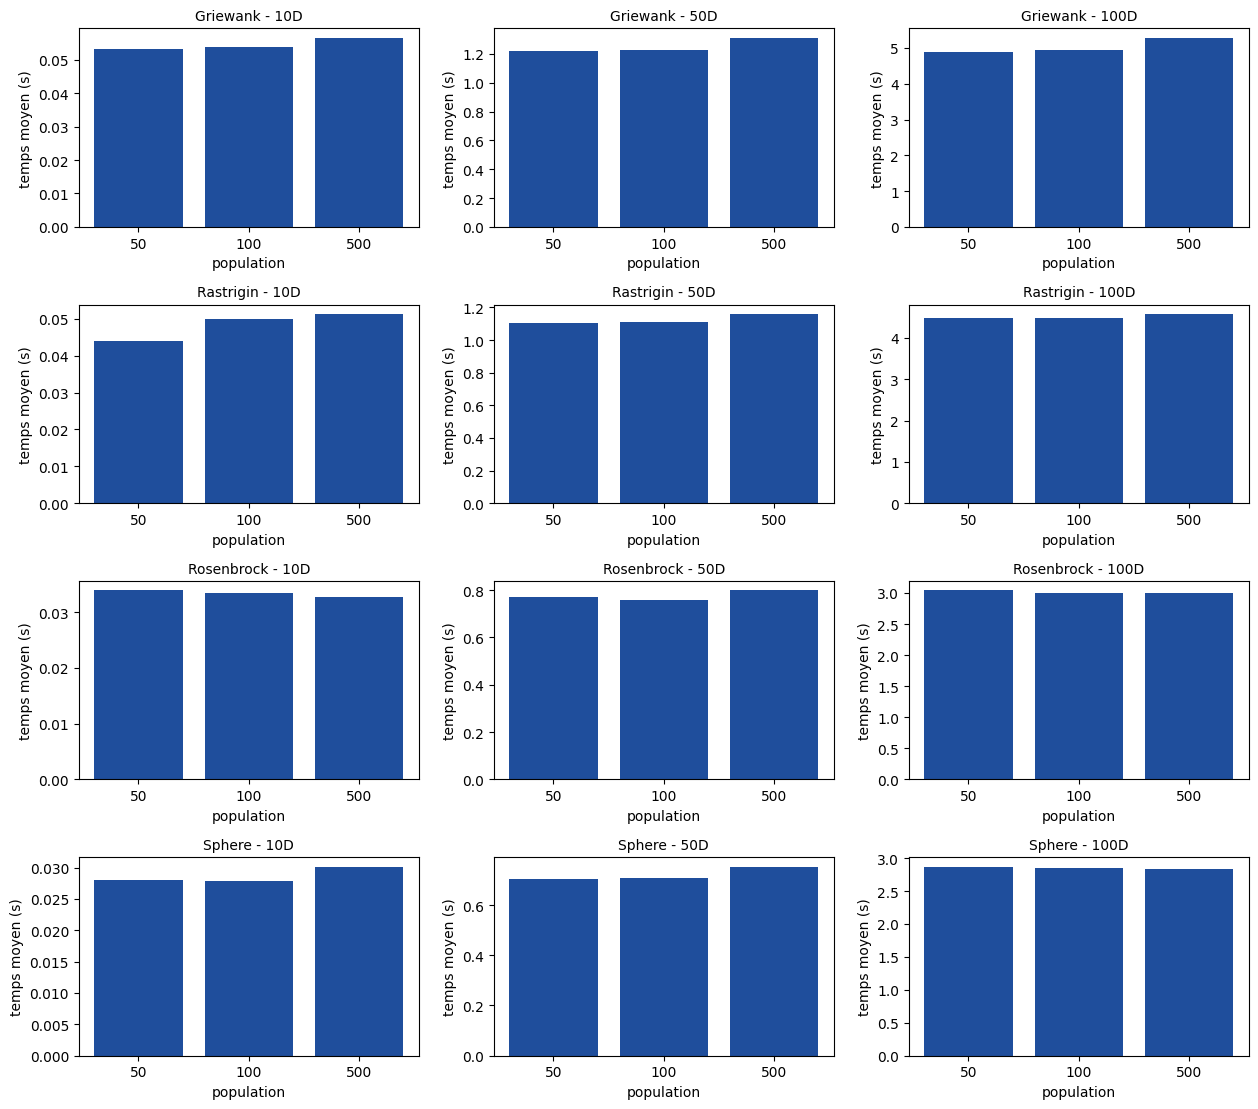

In [38]:
if summary_pso is not None:
    import matplotlib.pyplot as plt

    funcs = list(summary_pso["func"].unique())
    dims = sorted(summary_pso["dim"].unique())
    pops = sorted(summary_pso["pop"].unique())

    fig, axes = plt.subplots(len(funcs), len(dims), figsize=(4.2 * len(dims), 2.8 * len(funcs)), squeeze=False)

    for i, f in enumerate(funcs):
        for j, d in enumerate(dims):
            # Filter for the specific function and dimension
            subset = summary_pso[(summary_pso.func == f) & (summary_pso.dim == d)]
            
            # Group by 'pop' and calculate the mean to combine duplicate rows
            s = subset.groupby("pop").mean(numeric_only=True).reindex(pops)
            
            ax = axes[i][j]
            ax.bar([str(p) for p in pops], s["time_s"], color="#1f4e9c")
            ax.set_title(f"{f} - {d}D", fontsize=10)
            ax.set_xlabel("population")
            ax.set_ylabel("temps moyen (s)")

    plt.tight_layout()
    save_figure(plt.gcf(), "fig_pso_cpu_time_vs_pop.png")
    plt.show()


## 7. Traçabilité des campagnes terminées

Relecture des CSV et métadonnées : intégrité, grille, graines, FEs, builds et warm-up.
Le PSO GPU est mesuré dans la section suivante, puis contrôlé à la combinaison finale.


In [39]:
METRICS_OK = False
for algorithm in COMPLETED_RESULTS:
    frame = load_current_results(algorithm)
    print(algorithm, len(frame), "runs ; intégrité, protocole et échauffement vérifiés")
METRICS_OK = bool(COMPLETED_RESULTS)


de 720 runs ; intégrité, protocole et échauffement vérifiés
pso_cpu 360 runs ; intégrité, protocole et échauffement vérifiés


## 8. PSO GPU courant, comparaison et statistiques

La campagne PSO GPU est produite ici, puis combinée aux campagnes DE CPU/GPU et PSO CPU
de la même session : 1440 runs. L'analyse complète exige la grille du sujet et les quatre implémentations.

Les runs utilisent des flux séparés par implémentation (y compris entre DE CPU et PSO CPU) : le numéro de graine ne constitue pas un appariement.
Mann–Whitney bilatéral compare les distributions par configuration (144 tests, p par permutation
reproductible, 99 999 rééchantillonnages), avec une correction de Holm globale sur les 144 hypothèses.
Kruskal–Wallis compare les quatre groupes par configuration (36 tests asymptotiques, correction des
ex æquo ; Holm global sur 36). Les familles sont fixées avant les résultats. Aucun test ne mélange
les neuf configurations. Les tests supposent des runs indépendants ; n=10 limite la puissance et
la précision de l'approximation Kruskal–Wallis. Un résultat non significatif ne prouve pas l'équivalence.
La taille d'effet Mann–Whitney est positive si l'erreur du premier groupe tend à être plus élevée.


In [40]:
if RUN_FULL_SWEEPS and RUN_DE_GPU:
    run_sweep("pso_gpu")
else:
    print("Sweep PSO GPU non demandé ; aucune campagne historique importée.")


pso_gpu Sphere 10 50 terminé
pso_gpu Rastrigin 10 50 terminé
pso_gpu Rosenbrock 10 50 terminé
pso_gpu Griewank 10 50 terminé
pso_gpu Sphere 10 100 terminé
pso_gpu Rastrigin 10 100 terminé
pso_gpu Rosenbrock 10 100 terminé
pso_gpu Griewank 10 100 terminé
pso_gpu Sphere 10 500 terminé
pso_gpu Rastrigin 10 500 terminé
pso_gpu Rosenbrock 10 500 terminé
pso_gpu Griewank 10 500 terminé
pso_gpu Sphere 50 50 terminé
pso_gpu Rastrigin 50 50 terminé
pso_gpu Rosenbrock 50 50 terminé
pso_gpu Griewank 50 50 terminé
pso_gpu Sphere 50 100 terminé
pso_gpu Rastrigin 50 100 terminé
pso_gpu Rosenbrock 50 100 terminé
pso_gpu Griewank 50 100 terminé
pso_gpu Sphere 50 500 terminé
pso_gpu Rastrigin 50 500 terminé
pso_gpu Rosenbrock 50 500 terminé
pso_gpu Griewank 50 500 terminé
pso_gpu Sphere 100 50 terminé
pso_gpu Rastrigin 100 50 terminé
pso_gpu Rosenbrock 100 50 terminé
pso_gpu Griewank 100 50 terminé
pso_gpu Sphere 100 100 terminé
pso_gpu Rastrigin 100 100 terminé
pso_gpu Rosenbrock 100 100 terminé
pso_g

In [41]:
# Analyse — combinaison des quatre implémentations sur la grille commune du protocole.
ANALYSIS_OK = False
CAMPAIGN_VALIDATION_OK = False
ANALYSIS_ARTIFACTS.clear()
FIGURE_ARTIFACTS.clear()
PROTOCOL = dict(runs=10, dims=[10, 50, 100], pops=[50, 100, 500],
                funcs={4: "Sphere", 1: "Rastrigin", 2: "Rosenbrock", 3: "Griewank"})
if not RUN_FULL_SWEEPS or not RUN_DE_GPU:
    print("Analyse comparative ignorée : campagne complète CPU/GPU non demandée.")
else:
    if (RUNS, sorted(DIMS), sorted(POPS), FUNCS) != (PROTOCOL["runs"], PROTOCOL["dims"],
                                                     PROTOCOL["pops"], PROTOCOL["funcs"]):
        raise RuntimeError("Analyse réservée au protocole complet du brief (4 fonctions × "
                           "3 dimensions × 3 populations × 10 runs) : restaurer "
                           "FUNCS/DIMS/POPS/RUNS puis relancer les sweeps.")
    required = ("de", "pso_cpu", "pso_gpu")
    if any(a not in COMPLETED_RESULTS for a in required):
        raise RuntimeError("Campagnes courantes DE CPU/GPU et PSO CPU/GPU requises")
    metas = [json.loads(COMPLETED_RESULTS[a]["meta_path"].read_text()) for a in required]
    if any(m["session_id"] != SESSION_ID for m in metas) or any(m["environment"] != metas[0]["environment"] for m in metas):
        raise RuntimeError("Les campagnes doivent partager la session et l'environnement")
    df_all = pd.concat([load_current_results(a) for a in required], ignore_index=True)
    expected_impls = ["DE cpu", "DE gpu", "PSO cpu", "PSO gpu"]
    found_impls = sorted(df_all["algo"].unique())
    if found_impls != sorted(expected_impls):
        raise RuntimeError(f"Implémentations attendues {expected_impls} ; trouvées {found_impls} "
                           "(sweep DE GPU manquant ? activer RUN_DE_GPU=True et RUN_FULL_SWEEPS=True).")
    bias_by_name = {name: BIAS[f] for f, name in FUNCS.items()}
    expected_configs = {(FUNCS[f], d, p) for d in DIMS for p in POPS for f in FUNCS}
    for impl, group in df_all.groupby("algo"):
        if len(group) != len(expected_configs) * RUNS:
            raise RuntimeError(f"{impl} : {len(group)} lignes au lieu de "
                               f"{len(expected_configs) * RUNS}")
        if set(zip(group["func"], group["dim"], group["pop"])) != expected_configs:
            raise RuntimeError(f"{impl} : grille (fonction, dimension, population) incomplète")
        for key, sub in group.groupby(["func", "dim", "pop"]):
            if (sorted(zip(sub["run"], sub["seed"])) != [(r,1234+r) for r in range(RUNS)]):
                raise RuntimeError(f"{impl} {key} : runs ou graines hors protocole "
                                   f"(1234..{1234 + RUNS - 1} attendues)")
    recomputed = df_all["best"] - df_all["func"].map(bias_by_name)
    if (df_all["error"] - recomputed).abs().max() > 1e-9 * (1.0 + df_all["best"].abs().max()):
        raise RuntimeError("Colonne error incohérente avec best − biais")
    values = df_all[["best", "error", "time_ms"]].to_numpy()
    if not np.isfinite(values).all() or (df_all["time_ms"] <= 0).any():
        raise RuntimeError("Mesures non finies ou temps <= 0")
    df_all["success"] = df_all["error"] < 1e-8
    save_analysis(df_all, "results_all_impls.csv")
    ANALYSIS_OK = True
    print(f"{len(df_all)} runs combinés — 4 implémentations × {len(expected_configs)} "
          f"configurations × {RUNS} runs -> {RESULTS_DIR / 'results_all_impls.csv'}")


1440 runs combinés — 4 implémentations × 36 configurations × 10 runs -> /kaggle/working/de_pso_work/20261026T084908Z_93351482/results/results_all_impls.csv


In [42]:
# Analyse — synthèse qualité/temps par implémentation et vue d'ensemble.
if ANALYSIS_OK:
    summary_all = (df_all.groupby(["algo", "func", "dim", "pop"])
        .agg(runs=("run", "count"), mean_best=("best", "mean"), std_best=("best", "std"),
             median_best=("best", "median"), mean_error=("error", "mean"),
             std_error=("error", "std"), median_error=("error", "median"),
             success_rate=("success", "mean"),
             time_s=("time_ms", lambda s: s.mean() / 1000.0))
        .reset_index()
        .sort_values(["func", "dim", "pop", "algo"])
        .reset_index(drop=True))
    if len(summary_all) != 4 * len(expected_configs) or not summary_all["runs"].eq(RUNS).all():
        raise RuntimeError("Table de synthèse incomplète : 4 implémentations × 36 configurations "
                           "et 10 runs par cellule attendus")
    save_analysis(summary_all, "summary_all.csv")
    overview = (df_all.groupby("algo")
        .agg(runs=("run", "count"), success_rate=("success", "mean"),
             median_error=("error", "median"), mean_time_ms=("time_ms", "mean"))
        .reset_index()
        .sort_values("algo"))
    display(overview)
    display(summary_all)
else:
    print("Synthèse ignorée : analyse non exécutée.")


,algo,runs,success_rate,median_error,mean_time_ms
0,DE cpu,360,0.388889,0.056477,1180.125646
1,DE gpu,360,0.388889,0.050283,721.419204
2,PSO cpu,360,0.127778,6.095816,1620.854037
3,PSO gpu,360,0.119444,9.335422,421.334366


,algo,func,dim,pop,runs,mean_best,std_best,median_best,mean_error,std_error,median_error,success_rate,time_s
0,DE cpu,Griewank,10,50,10,-180.000000,0.000000,-180.000000,0.000000,0.000000,0.000000,1.0,0.040972
1,DE gpu,Griewank,10,50,10,-180.000000,0.000000,-180.000000,0.000000,0.000000,0.000000,1.0,0.056030
2,PSO cpu,Griewank,10,50,10,-179.917822,0.035637,-179.920020,0.082178,0.035637,0.079980,0.0,0.053069
3,PSO gpu,Griewank,10,50,10,-179.926472,0.055236,-179.926240,0.073528,0.055236,0.073760,0.0,0.045474
4,DE cpu,Griewank,10,100,10,-180.000000,0.000000,-180.000000,0.000000,0.000000,0.000000,1.0,0.041742
...,...,...,...,...,...,...,...,...,...,...,...,...,...
139,PSO gpu,Sphere,100,100,10,2039.955810,2796.693071,1359.913274,2489.955810,2796.693071,1809.913274,0.1,0.349137
140,DE cpu,Sphere,100,500,10,-449.903684,0.005667,-449.904811,0.096316,0.005667,0.095189,0.0,1.939155
141,DE gpu,Sphere,100,500,10,-449.900231,0.008080,-449.900352,0.099769,0.008080,0.099648,0.0,0.226717
142,PSO cpu,Sphere,100,500,10,-151.488863,427.788574,-449.490211,298.511137,427.788574,0.509789,0.0,2.840596


In [43]:
# Analyse — temps CPU/GPU par configuration et accélération (conventions identiques).
speedups = None
if ANALYSIS_OK:
    times = summary_all.pivot_table(index=["func", "dim", "pop"], columns="algo", values="time_s")
    speedups = pd.DataFrame(index=times.index)
    for cpu_impl, gpu_impl in (("DE cpu", "DE gpu"), ("PSO cpu", "PSO gpu")):
        if cpu_impl in times.columns and gpu_impl in times.columns:
            speedups[f"{cpu_impl} / {gpu_impl}"] = times[cpu_impl] / times[gpu_impl]
    speedups = speedups.reset_index()
    if len(speedups) != len(expected_configs) or speedups.isna().any().any():
        raise RuntimeError("Comparatif de temps incomplet ou valeurs absentes")
    save_analysis(speedups, "speedup_all.csv")
    display(speedups)
    display(speedups.drop(columns=["func", "dim", "pop"]).describe().round(3))
else:
    print("Temps ignorés : analyse non exécutée.")


,func,dim,pop,DE cpu / DE gpu,PSO cpu / PSO gpu
0,Griewank,10,50,0.731252,1.167001
1,Griewank,10,100,1.198611,1.819038
2,Griewank,10,500,7.343582,9.147650
3,Griewank,50,50,0.676867,1.522819
4,Griewank,50,100,1.051394,2.106709
5,Griewank,50,500,6.020711,10.388701
6,Griewank,100,50,0.699484,1.595909
7,Griewank,100,100,1.057327,2.144312
8,Griewank,100,500,6.276453,10.225556
9,Rastrigin,10,50,0.871905,1.346701


,DE cpu / DE gpu,PSO cpu / PSO gpu
count,36.000,36.000
mean,3.392,7.045
std,3.199,6.314
min,0.677,1.167
25%,1.037,2.259
50%,1.496,4.077
75%,7.048,10.579
max,9.747,25.211


In [44]:
# Runs use independent streams across implementations: no artificial seed pairing.
# Families are fixed before results: all 144 pairwise hypotheses, all 36 omnibus tests.
stats_mannwhitney = stats_kruskal = None
if ANALYSIS_OK:
    from scipy import stats as spstats
    PAIRS = [("DE cpu","PSO cpu"),("DE gpu","PSO gpu"),("DE cpu","DE gpu"),("PSO cpu","PSO gpu")]
    ALL_IMPLS = ["DE cpu","DE gpu","PSO cpu","PSO gpu"]
    def holm_adjust(pvalues):
        p=np.asarray(pvalues,dtype=float); order=np.argsort(p); adjusted=np.empty(len(p)); running=0.0
        for position,index in enumerate(order):
            running=max(running,min(1.0,(len(p)-position)*p[index]));adjusted[index]=running
        return adjusted
    pair_rows, omnibus_rows = [], []
    # Permutation p-values handle zeros/ties at n=10 without the no-tie exact-U assumption.
    # Reproducible Monte Carlo approximation, 99,999 resamples (or exhaustive if fewer).
    for (func,dim,pop), block in df_all.groupby(["func","dim","pop"]):
        groups={impl:block.loc[block.algo==impl,"error"].to_numpy() for impl in ALL_IMPLS}
        for a,b in PAIRS:
            x,y=groups[a],groups[b]
            if np.all(np.concatenate([x,y])==x[0]):
                u,pvalue=0.5*len(x)*len(y),1.0
            else:
                method=spstats.PermutationMethod(n_resamples=99999,random_state=20261027)
                test=spstats.mannwhitneyu(x,y,alternative="two-sided",method=method)
                u,pvalue=float(test.statistic),float(test.pvalue)
            pair_rows.append(dict(pair=f"{a} vs {b}",func=func,dim=dim,pop=pop,n_a=len(x),n_b=len(y),
                                  U=u,p_value=pvalue,rank_biserial=2*u/(len(x)*len(y))-1))
        all_values=np.concatenate(list(groups.values()))
        if np.all(all_values==all_values[0]):
            h,pvalue=0.0,1.0
        else:
            test=spstats.kruskal(*groups.values());h,pvalue=float(test.statistic),float(test.pvalue)
        omnibus_rows.append(dict(func=func,dim=dim,pop=pop,H=h,p_value=pvalue,
                                  epsilon2=h/(len(all_values)-1),method="asymptotic, ties corrected"))
    stats_mannwhitney=pd.DataFrame(pair_rows);stats_kruskal=pd.DataFrame(omnibus_rows)
    for frame,name in [(stats_mannwhitney,"stats_mannwhitney.csv"),(stats_kruskal,"stats_kruskal.csv")]:
        if not np.isfinite(frame.p_value).all():raise RuntimeError("p-values non finies")
        frame["p_holm"]=holm_adjust(frame.p_value)
        frame["significant_05"]=frame.p_holm<0.05
        save_analysis(frame, name)
        display(frame)


,pair,func,dim,pop,n_a,n_b,U,p_value,rank_biserial,p_holm,significant_05
0,DE cpu vs PSO cpu,Griewank,10,50,10,10,0.0,0.00004,-1.00,0.00576,True
1,DE gpu vs PSO gpu,Griewank,10,50,10,10,0.0,0.00004,-1.00,0.00576,True
2,DE cpu vs DE gpu,Griewank,10,50,10,10,50.0,1.00000,0.00,1.00000,False
3,PSO cpu vs PSO gpu,Griewank,10,50,10,10,64.0,0.31096,0.28,1.00000,False
4,DE cpu vs PSO cpu,Griewank,10,100,10,10,0.0,0.00004,-1.00,0.00576,True
...,...,...,...,...,...,...,...,...,...,...,...
139,PSO cpu vs PSO gpu,Sphere,100,100,10,10,35.0,0.28020,-0.30,1.00000,False
140,DE cpu vs PSO cpu,Sphere,100,500,10,10,29.0,0.12204,-0.42,1.00000,False
141,DE gpu vs PSO gpu,Sphere,100,500,10,10,24.0,0.05272,-0.52,1.00000,False
142,DE cpu vs DE gpu,Sphere,100,500,10,10,37.0,0.35470,-0.26,1.00000,False


,func,dim,pop,H,p_value,epsilon2,method,p_holm,significant_05
0,Griewank,10,50,33.768232,2.217425e-07,0.865852,"asymptotic, ties corrected",0.000008,True
1,Griewank,10,100,33.522444,2.498743e-07,0.859550,"asymptotic, ties corrected",0.000009,True
2,Griewank,10,500,5.581463,1.338466e-01,0.143114,"asymptotic, ties corrected",0.844323,False
3,Griewank,50,50,33.041560,3.156313e-07,0.847219,"asymptotic, ties corrected",0.000010,True
4,Griewank,50,100,31.131391,7.975844e-07,0.798241,"asymptotic, ties corrected",0.000022,True
5,Griewank,50,500,29.916585,1.436953e-06,0.767092,"asymptotic, ties corrected",0.000034,True
6,Griewank,100,50,33.522444,2.498743e-07,0.859550,"asymptotic, ties corrected",0.000009,True
7,Griewank,100,100,31.425952,6.914148e-07,0.805794,"asymptotic, ties corrected",0.000019,True
8,Griewank,100,500,20.533171,1.315929e-04,0.526492,"asymptotic, ties corrected",0.001448,True
9,Rastrigin,10,50,26.568921,7.248842e-06,0.681254,"asymptotic, ties corrected",0.000109,True


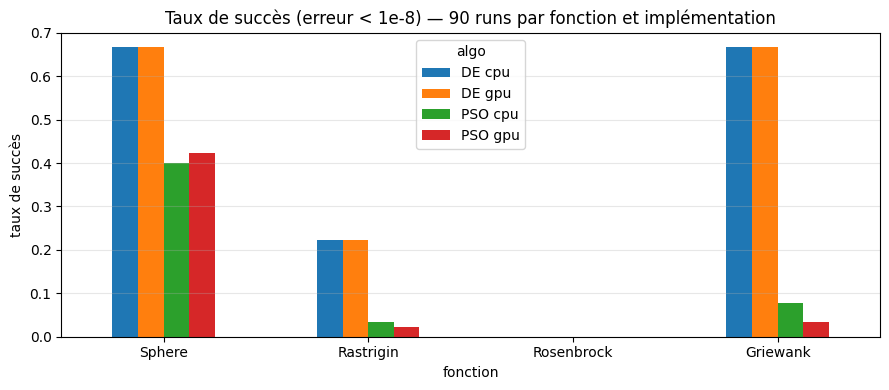

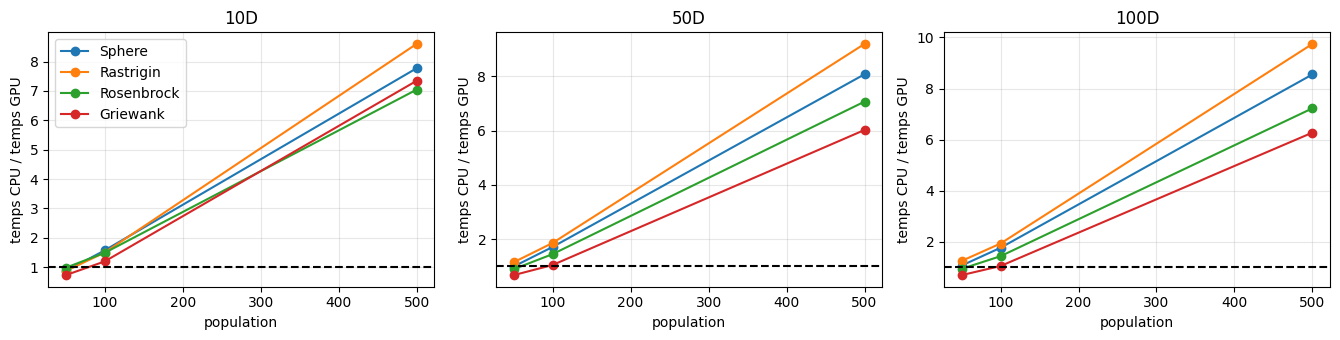

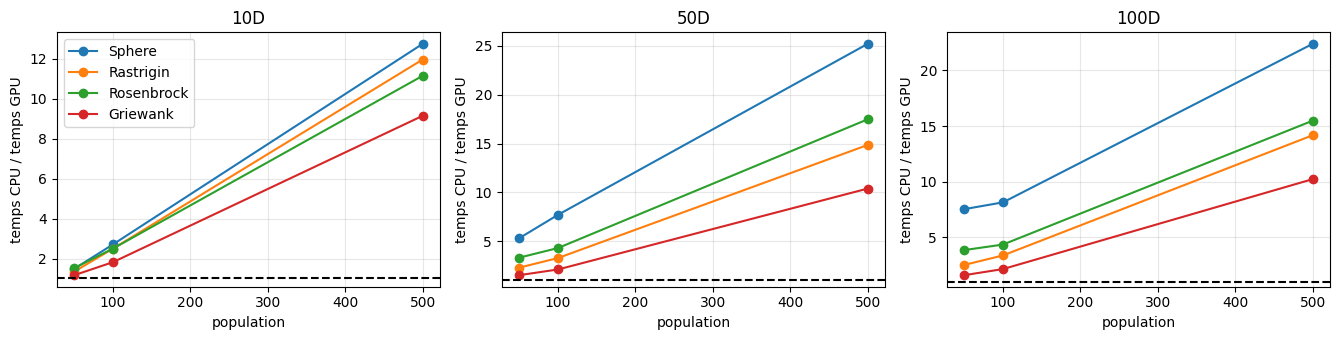

In [45]:
# Analyse — figures : taux de succès et accélérations CPU/GPU par population.
if ANALYSIS_OK:
    import matplotlib.pyplot as plt

    ordered_funcs = [FUNCS[f] for f in (4, 1, 2, 3)]   # Sphere, Rastrigin, Rosenbrock, Griewank
    success = (df_all.groupby(["algo", "func"])["success"].mean()
               .unstack("algo").reindex(ordered_funcs))
    if success.isna().any().any():
        raise RuntimeError("Taux de succès incomplets")
    ax = success.plot.bar(figsize=(9, 4), rot=0)
    ax.set(title=f"Taux de succès (erreur < 1e-8) — {len(DIMS) * len(POPS) * RUNS} runs par fonction et implémentation",
           xlabel="fonction", ylabel="taux de succès")
    ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    save_figure(plt.gcf(), "fig_success_rate.png")
    plt.show()

    times = summary_all.pivot_table(index=["func", "dim", "pop"], columns="algo", values="time_s")
    for tag, (cpu_impl, gpu_impl) in (("de", ("DE cpu", "DE gpu")), ("pso", ("PSO cpu", "PSO gpu"))):
        if cpu_impl not in times.columns or gpu_impl not in times.columns:
            continue
        speedup = (times[cpu_impl] / times[gpu_impl]).rename("speedup").reset_index()
        fig, axes = plt.subplots(1, len(DIMS), figsize=(4.5 * len(DIMS), 3.5), squeeze=False)
        for j, dim in enumerate(sorted(DIMS)):
            for func in ordered_funcs:
                part = speedup[(speedup["func"] == func) & (speedup["dim"] == dim)].sort_values("pop")
                axes[0][j].plot(part["pop"], part["speedup"], marker="o", label=func)
            axes[0][j].axhline(1.0, color="black", linestyle="--")
            axes[0][j].set(title=f"{dim}D", xlabel="population", ylabel="temps CPU / temps GPU")
            axes[0][j].grid(alpha=0.3)
            if j == 0:
                axes[0][j].legend()
        fig.tight_layout()
        save_figure(fig, f"fig_speedup_{tag}.png")
        plt.show()
else:
    print("Figures ignorées : analyse non exécutée.")


## 9. Validation et archive

`TECHNICAL_VALIDATION_OK` atteste les tests et l'intégrité des builds et campagnes présentes.
`CAMPAIGN_VALIDATION_OK` exige les quatre campagnes, les statistiques et les livrables complets,
avec relecture et recalcul des synthèses et accélérations. Ces drapeaux ne remplacent pas
l'interprétation scientifique des résultats. L'archive contient uniquement les livrables explicitement
sélectionnés de cette session, les sources, leurs empreintes et un manifeste vérifié.


In [46]:
TECHNICAL_VALIDATION_OK = False
CAMPAIGN_VALIDATION_OK = False
if not (SMOKE_OK and ALGORITHM_TESTS_OK):
    raise RuntimeError("Tests obligatoires non exécutés")
for name,record in BUILDS.items():
    verify_sources(record["directory"],record["hashes"])
    if hashlib.sha256(record["exe"].read_bytes()).hexdigest()!=record["exe_sha256"]:
        raise RuntimeError(f"Exécutable modifié : {name}")
for algorithm in COMPLETED_RESULTS:
    load_current_results(algorithm)
TECHNICAL_VALIDATION_OK = True
print("TECHNICAL_VALIDATION_OK : builds, tests et intégrité ; ne valide pas une campagne scientifique.")
if RUN_FULL_SWEEPS:
    if not RUN_DE_GPU:
        print("Campagnes CPU contrôlées ; validation des quatre implémentations indisponible sans GPU.")
    else:
        if not ANALYSIS_OK or set(COMPLETED_RESULTS)!={"de","pso_cpu","pso_gpu"}:
            raise RuntimeError("Analyse ou campagnes incomplètes")
        required={"results_all_impls.csv":1440,"summary_all.csv":144,"stats_mannwhitney.csv":144,
                  "stats_kruskal.csv":36,"speedup_all.csv":36}
        for name,rows in required.items():
            record=ANALYSIS_ARTIFACTS.get(name);path=RESULTS_DIR/name
            if (record is None or record["rows"]!=rows or
                    hashlib.sha256(path.read_bytes()).hexdigest()!=record["sha256"] or len(pd.read_csv(path))!=rows):
                raise RuntimeError(f"Livrable absent ou modifié : {name}")
        # Recompute key derived quantities from the authenticated current-session inputs.
        data=pd.read_csv(RESULTS_DIR/"results_all_impls.csv")
        expected=pd.concat([load_current_results(a) for a in ("de","pso_cpu","pso_gpu")],ignore_index=True)
        pd.testing.assert_frame_equal(data[COLS],expected[COLS],check_exact=False,rtol=1e-12,atol=1e-12)
        if not data.success.eq(data.error<1e-8).all():raise RuntimeError("Taux de succès incohérents")
        group=data.groupby(["algo","func","dim","pop"])
        expected_summary=group.agg(mean_best=("best","mean"),mean_error=("error","mean"),
                                   success_rate=("success","mean"),time_s=("time_ms",lambda s:s.mean()/1000)).sort_index()
        stored=pd.read_csv(RESULTS_DIR/"summary_all.csv").set_index(["algo","func","dim","pop"]).sort_index()
        pd.testing.assert_frame_equal(stored[expected_summary.columns],expected_summary,check_exact=False,rtol=1e-10,atol=1e-12)
        times=stored.time_s.unstack("algo")
        expected_speed=pd.DataFrame({"DE cpu / DE gpu":times["DE cpu"]/times["DE gpu"],
                                     "PSO cpu / PSO gpu":times["PSO cpu"]/times["PSO gpu"]}).sort_index()
        stored_speed=pd.read_csv(RESULTS_DIR/"speedup_all.csv").set_index(["func","dim","pop"]).sort_index()
        pd.testing.assert_frame_equal(stored_speed,expected_speed,check_exact=False,rtol=1e-10,atol=1e-12)
        for name in ("fig_success_rate.png","fig_speedup_de.png","fig_speedup_pso.png"):
            if name not in FIGURE_ARTIFACTS or hashlib.sha256((RESULTS_DIR/name).read_bytes()).hexdigest()!=FIGURE_ARTIFACTS[name]:
                raise RuntimeError(f"Figure absente ou modifiée : {name}")
        CAMPAIGN_VALIDATION_OK = True
        print("CAMPAIGN_VALIDATION_OK : campagne complète et livrables vérifiés ; interprétation statistique à documenter.")
validation=dict(session_id=SESSION_ID,technical=TECHNICAL_VALIDATION_OK,campaign=CAMPAIGN_VALIDATION_OK,
                algorithm_tests=ALGORITHM_TESTS_OK,gpu_tests_executed=RUN_DE_GPU,
                analysis_artifacts=ANALYSIS_ARTIFACTS,figures=FIGURE_ARTIFACTS)
(RESULTS_DIR/"validation.json").write_text(json.dumps(validation,indent=2))


TECHNICAL_VALIDATION_OK : builds, tests et intégrité ; ne valide pas une campagne scientifique.
CAMPAIGN_VALIDATION_OK : campagne complète et livrables vérifiés ; interprétation statistique à documenter.


1162

In [47]:
import zipfile
# A new session has a new directory. Only named, current-session artifacts are packaged.
if TECHNICAL_VALIDATION_OK and COMPLETED_RESULTS:
    names={"algorithm_tests.txt","smoke_execution.json","validation.json"} | set(ANALYSIS_ARTIFACTS) | set(FIGURE_ARTIFACTS)
    for algorithm,record in COMPLETED_RESULTS.items():
        load_current_results(algorithm)
        names.update([record["path"].name,record["meta_path"].name,f"runs_{algorithm}.txt"])
        meta=json.loads(record["meta_path"].read_text())
        if meta["warmup"]:names.add(meta["warmup"]["csv"])
    if CAMPAIGN_VALIDATION_OK:
        names.update(["fig_success_rate.png","fig_speedup_de.png","fig_speedup_pso.png"])
    entries={f"results/{name}":RESULTS_DIR/name for name in sorted(names)}
    for directory,tag,hashes in [(DE_SRC,"de",DE_HASHES),(PSO_SRC,"pso",PSO_HASHES)]:
        for name in [*hashes,"sources.sha256.json"]:entries[f"sources/{tag}/{name}"]=directory/name
    notebook=Path.cwd()/"project-cuda-de-pso.ipynb"
    if notebook.exists():entries[notebook.name]=notebook
    for name,record in ANALYSIS_ARTIFACTS.items():
        if hashlib.sha256((RESULTS_DIR/name).read_bytes()).hexdigest()!=record["sha256"]:
            raise RuntimeError(f"Analyse modifiée après validation : {name}")
    for name,digest in FIGURE_ARTIFACTS.items():
        if hashlib.sha256((RESULTS_DIR/name).read_bytes()).hexdigest()!=digest:
            raise RuntimeError(f"Figure modifiée après validation : {name}")
    ZIP_PATH=WORK_DIR/f"resultats_de_pso_{SESSION_ID}.zip"
    manifest={}
    with zipfile.ZipFile(ZIP_PATH,"w",zipfile.ZIP_DEFLATED) as archive:
        for name,path in entries.items():
            data=path.read_bytes();manifest[name]=hashlib.sha256(data).hexdigest();archive.writestr(name,data)
        archive.writestr("manifest.json",json.dumps(manifest,indent=2))
    with zipfile.ZipFile(ZIP_PATH) as archive:
        if set(archive.namelist())!=set(manifest)|{"manifest.json"}:raise RuntimeError("Contenu inattendu")
        if json.loads(archive.read("manifest.json"))!=manifest:raise RuntimeError("Manifeste incohérent")
        for name,digest in manifest.items():
            if hashlib.sha256(archive.read(name)).hexdigest()!=digest:raise RuntimeError(f"Archive altérée : {name}")
    print("Archive :",ZIP_PATH,"; campagne complète :",CAMPAIGN_VALIDATION_OK)
else:
    print("Archive non produite : aucune campagne demandée.")


Archive : /kaggle/working/de_pso_work/20261026T084908Z_93351482/resultats_de_pso_20261026T084908Z_93351482.zip ; campagne complète : True


### Exécution finale sur une machine NVIDIA

1. Activer le GPU ; fixer `RUN_DE_GPU=True`, `RUN_FULL_SWEEPS=True`.
2. Exécuter toutes les cellules dans l'ordre ; les quatre implémentations sont remesurées.
3. Vérifier les deux drapeaux de validation, puis récupérer l'archive dans `de_pso_work/<session>/`.
4. Conserver le notebook exécuté avec l'archive. La copie sur disque incluse dans l'archive peut
   précéder la sauvegarde des dernières sorties ; exporter séparément le notebook exécuté.

Sans GPU, `RUN_DE_GPU=False` permet les tests et campagnes CPU ; aucune analyse à quatre
implémentations ni validation de campagne complète n'est annoncée.


## Choix retenus et limites

Cette version corrige le DE, harmonise les mesures et produit une référence de comparaison.
Les shifts sont synthétiques, reproductibles dans un environnement fixé ; ils ne reproduisent
pas les fichiers officiels CEC2005. Les comparaisons numériques avec les tableaux de l’article
doivent donc expliciter cette différence et les 10 runs du sujet contre 25 dans l’article.
Les optimisations CUDA avancées et les variantes DE restent des expériences distinctes.
La vérification CUDA exige une exécution sur NVIDIA ; les tests CPU ne la remplacent pas.
